# 1. Data Loading

## 1.1 Selected Datasets

| Domain | Dataset | ID | Link |
|---|---|---|---|
| Housing & Development | Housing Maintenance Code Complaints and Problems (H6) | `ygpa-z7cr` | https://data.cityofnewyork.us/d/ygpa-z7cr |
| Transportation | SIRTA Crash Data (T4) | `xeqp-qz8h` | https://data.cityofnewyork.us/d/xeqp-qz8h |

**Why this pair:** both datasets share geographic attributes (borough, ZIP code, community board,
latitude/longitude) and a date field, so they can be integrated at a common geographic and temporal
level. Together they let us ask whether neighborhoods with poor housing conditions are also exposed
to more serious traffic crashes.

## 1.2 Loading Method: API instead of a full download

- The full housing dataset has **16.4 million rows**, which is too large to download or load in Colab
  memory. We therefore used the NYC Open Data **SODA API** with filters, as recommended in the
  project description (Listing 2).
- We requested data in **JSON** instead of CSV, because the CSV response for the crash dataset failed
  to parse (rows had an inconsistent number of fields caused by text fields). JSON is used for both
  datasets for consistency.
- Data was downloaded **page by page**. The offset advances by the number of rows actually returned,
  because the API can return fewer rows than requested; this guarantees no rows are skipped.
- `$order=:id` keeps the row order stable, so the download is **reproducible**.
- Every download is **verified** against a `count(*)` query to the API to confirm it is complete.
- Temporary server errors ("Service unavailable") are **retried automatically** with an increasing
  wait time, so a short API outage does not break the download.

## 1.3 Time Window: 2022–2025

Crashes per year in the T4 dataset:

| Year | Crashes |
|---|---|
| 2022 | 2,879 |
| 2023 | 3,016 |
| 2024 | 3,116 |
| 2025 | 2,947 |
| 2026 | 1,352 (partial year) |
| No date | 444 |

- **2022–2025 selected:** four complete years. This gives about 12,000 crashes, which is enough for
  a meaningful aggregation, and allows trend analysis over time.
- **2026 excluded:** it is a partial year, and including it would make 2026 look artificially low.
- **444 undated crashes excluded:** without a date they cannot be assigned to a year (documented as
  a known data issue).
- The **same window** is applied to the housing dataset so both domains cover identical periods.
- The T4 dataset appears to record only **serious crashes** (columns track severe injuries and
  fatalities), which explains its small size compared to general NYC crash data.

## 1.4 Column Selection

- **Crashes:** all columns kept (the dataset is small); only the four API metadata columns
  (`:id`, `:version`, `:created_at`, `:updated_at`) were dropped, since they are not real data.
- **Housing:** 17 of 33 columns selected with `$select` to reduce memory, keeping:
  - **Time:** `received_date`
  - **Geography:** `borough`, `post_code`, `community_board`, `nta`, `latitude`, `longitude`
  - **Categories:** `major_category`, `minor_category`, `type`, `unit_type`, `space_type`
  - **Status:** `complaint_status`, `problem_status`
  - **IDs and duplicate handling:** `problem_id`, `complaint_id`, `problem_duplicate_flag`

## 1.5 Loaded Data Summary

| Dataset | Years | Rows | Columns |
|---|---|---|---|
| Crashes (T4) | 2022–2025 | 11,958 | 23 |
| Housing (H6) | 2022–2025 | 3,160,386 | 17 |

Housing rows per year:

| Year | Rows |
|---|---|
| 2022 | 733,471 |
| 2023 | 747,466 |
| 2024 | 823,169 |
| 2025 | 856,280 |

**Note:** in the housing dataset, each row is a **problem**, not a complaint. One complaint can contain
several problems (e.g., no heat and a leak in the same call). This matters when counting.

**Data saving:** housing data is saved to Google Drive year by year, so a Colab disconnection does not
require re-downloading completed years.

In [ ]:
# ============================================================
# Load T4: SIRTA Crash data (2022–2025)
# ============================================================
import pandas as pd
import requests
import time

TRANSPORT_ID  = 'xeqp-qz8h'
TRANSPORT_URL = f'https://data.cityofnewyork.us/resource/{TRANSPORT_ID}.json'
API_META_COLS = [':id', ':version', ':created_at', ':updated_at']

# 2026 excluded (partial year); rows with no crash_date excluded automatically by this filter
TRANSPORT_WHERE = "crash_date >= '2022-01-01T00:00:00' AND crash_date < '2026-01-01T00:00:00'"


def get_row_count(url, where_clause, max_retries=6):
    """Ask the API how many rows match the filter (used to verify the download), with retries."""
    for attempt in range(1, max_retries + 1):
        try:
            result = requests.get(url, params={'$select': 'count(*)', '$where': where_clause}, timeout=120).json()
            if isinstance(result, dict):
                raise RuntimeError(result.get('message', result))
            return int(list(result[0].values())[0])
        except Exception as err:
            if attempt == max_retries:
                raise
            wait = 10 * 2 ** (attempt - 1)
            print(f'    Error fetching count: {err}. Retry {attempt}/{max_retries} in {wait}s...')
            time.sleep(wait)


def load_socrata_json(url, params, page_size=50_000, max_retries=6):
    """Page through the API, advancing by the rows actually returned (no skipped rows), with retries."""
    chunks, offset = [], 0
    while True:
        page_params = {**params, '$limit': page_size, '$offset': offset}

        for attempt in range(1, max_retries + 1):
            try:
                data = requests.get(url, params=page_params, timeout=300).json()
                if isinstance(data, dict):
                    raise RuntimeError(data.get('message', data))
                break
            except Exception as err:
                if attempt == max_retries:
                    raise
                wait = 10 * 2 ** (attempt - 1)
                print(f'    Error at offset {offset:,}: {err}. Retry {attempt}/{max_retries} in {wait}s...')
                time.sleep(wait)

        if not data:
            break
        chunks.append(pd.DataFrame(data))
        offset += len(data)
        print(f'  Loaded {offset:,} rows...')
    return pd.concat(chunks, ignore_index=True)


transport_expected = get_row_count(TRANSPORT_URL, TRANSPORT_WHERE)
print(f'Expecting {transport_expected:,} rows')

df_transport = load_socrata_json(TRANSPORT_URL, {'$where': TRANSPORT_WHERE, '$order': ':id'})
df_transport = df_transport.drop(columns=API_META_COLS, errors='ignore')

print(f'\nRows: {len(df_transport):,} / {transport_expected:,} | Complete: {len(df_transport) == transport_expected}')
print(f'Columns: {df_transport.shape[1]}')

df_transport.to_csv('transport_2022_2025.csv', index=False)
print('Saved transport_2022_2025.csv')

Expecting 11,958 rows
  Loaded 11,958 rows...

Rows: 11,958 / 11,958 | Complete: True
Columns: 23
Saved transport_2022_2025.csv


In [ ]:
# Crashes per year across the whole T4 dataset (justifies the 2022–2025 window)
per_year = requests.get(TRANSPORT_URL, params={
    '$select': 'date_extract_y(crash_date) AS year, count(*) AS n',
    '$group':  'year',
    '$order':  'year',
}, timeout=120).json()
print(pd.DataFrame(per_year))

   year     n
0  2022  2879
1  2023  3016
2  2024  3116
3  2025  2947
4  2026  1352
5   NaN   444


In [ ]:
# ============================================================
# Load Housing: Maintenance Code Complaints and Problems (2022–2025)
# Saved year by year to Google Drive so a disconnect doesn't lose progress
# ============================================================
import os
import pandas as pd
import requests
from google.colab import drive

drive.mount('/content/drive')
SAVE_DIR = '/content/drive/MyDrive/DEV_project_data'
os.makedirs(SAVE_DIR, exist_ok=True)

HOUSING_ID  = 'ygpa-z7cr'
HOUSING_URL = f'https://data.cityofnewyork.us/resource/{HOUSING_ID}.json'
YEARS = [2022, 2023, 2024, 2025]

# Only the columns needed for EDA, cleaning, integration and research questions
HOUSING_COLS = ('received_date, problem_id, complaint_id, borough, post_code, '
                'community_board, unit_type, space_type, type, major_category, '
                'minor_category, complaint_status, problem_status, '
                'problem_duplicate_flag, latitude, longitude, nta')


def get_row_count(url, where_clause):
    """Ask the API how many rows match the filter (used to verify the download)."""
    result = requests.get(url, params={'$select': 'count(*)', '$where': where_clause},
                          timeout=120).json()
    if isinstance(result, dict):
        raise ValueError(result)
    return int(list(result[0].values())[0])


import time

def load_socrata_json(url, params, page_size=50_000, max_retries=6):
    """
    Page through the API, advancing by the rows actually returned (no skipped rows).
    Temporary server errors are retried with an increasing wait (10s, 20s, 40s, ...).
    """
    chunks, offset = [], 0
    while True:
        page_params = {**params, '$limit': page_size, '$offset': offset}

        for attempt in range(1, max_retries + 1):
            try:
                data = requests.get(url, params=page_params, timeout=300).json()
                if isinstance(data, dict):          # API error message, e.g. service-unavailable
                    raise RuntimeError(data.get('message', data))
                break                               # success, so stop retrying
            except Exception as err:
                if attempt == max_retries:
                    raise                           # give up after the last attempt
                wait = 10 * 2 ** (attempt - 1)
                print(f'    Error at offset {offset:,}: {err}. Retry {attempt}/{max_retries} in {wait}s...')
                time.sleep(wait)

        if not data:                                # no more rows
            break
        chunks.append(pd.DataFrame(data))
        offset += len(data)
        print(f'    Loaded {offset:,} rows...')
    return pd.concat(chunks, ignore_index=True)


for year in YEARS:
    out_path = f'{SAVE_DIR}/housing_{year}.csv'
    if os.path.exists(out_path):
        print(f'{year}: already saved, skipping')
        continue

    where = f"received_date >= '{year}-01-01T00:00:00' AND received_date < '{year + 1}-01-01T00:00:00'"
    expected = get_row_count(HOUSING_URL, where)
    print(f'{year}: expecting {expected:,} rows')

    df_year = load_socrata_json(HOUSING_URL, {'$where': where, '$select': HOUSING_COLS, '$order': ':id'})

    if len(df_year) != expected:                      # don't save an incomplete year
        raise ValueError(f'{year}: got {len(df_year):,}, expected {expected:,}. Re-run this cell.')

    df_year.to_csv(out_path, index=False)
    print(f'{year}: saved {len(df_year):,} rows\n')

# Combine all years into one DataFrame
df_housing = pd.concat([pd.read_csv(f'{SAVE_DIR}/housing_{y}.csv', low_memory=False) for y in YEARS],
                       ignore_index=True)
print(f'\nHousing total: {df_housing.shape[0]:,} rows × {df_housing.shape[1]} columns')

Mounted at /content/drive
2022: already saved, skipping
2023: already saved, skipping
2024: already saved, skipping
2025: already saved, skipping

Housing total: 3,160,386 rows × 17 columns


# 2. Exploratory Data Analysis (EDA)

Before cleaning, we explore each dataset to understand its structure and to **identify the problems
that the cleaning step must fix**. Every cleaning decision in Section 3 refers back to a finding here.

For each dataset we check:
1. **Structure:** rows, columns, data types, memory
2. **Missing values:** count and percentage per column
3. **Duplicates:** fully duplicated rows and duplicated IDs
4. **Categorical distributions:** boroughs, categories, statuses
5. **Temporal patterns:** records per month, seasonality
6. **Geographic validity:** ZIP codes and coordinates inside NYC
7. **Numeric distributions and outliers** (crashes)

Finally, we compare the **integration keys** (borough, ZIP, community board, date) across both
datasets to see what must be standardized before they can be joined.

**Note:** EDA does not modify the data. Any type conversions here are temporary, for plotting only.

In [6]:
# ============================================================
# 2.1 Setup: libraries, data reload, helper functions
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)

SAVE_DIR       = '/content/drive/MyDrive/DEV_project_data'
TRANSPORT_FILE = f'{SAVE_DIR}/transport_2022_2025.csv'
YEARS          = [2022, 2023, 2024, 2025]

# Keep a copy of the crash data on Drive (the /content copy is deleted when the session ends)
if not os.path.exists(TRANSPORT_FILE):
    df_transport.to_csv(TRANSPORT_FILE, index=False)

# Reload from Drive so the EDA still works after a session restart.
# Reading from CSV also lets pandas infer numeric types (the JSON API returned everything as text).
df_transport = pd.read_csv(TRANSPORT_FILE, low_memory=False)
if 'df_housing' not in globals():
    df_housing = pd.concat([pd.read_csv(f'{SAVE_DIR}/housing_{y}.csv', low_memory=False)
                            for y in YEARS], ignore_index=True)

# NYC bounding box, used to flag coordinates that are impossible for NYC
NYC_LAT = (40.49, 40.92)
NYC_LON = (-74.27, -73.68)


def dataset_overview(df, name):
    """Print size and duplicate info, and return a per-column summary table."""
    print(f'===== {name} =====')
    print(f'Rows: {len(df):,} | Columns: {df.shape[1]} | '
          f'Memory: {df.memory_usage(deep=True).sum() / 1e6:,.0f} MB')
    print(f'Fully duplicated rows: {df.duplicated().sum():,}')
    return pd.DataFrame({
        'dtype':     df.dtypes.astype(str),
        'missing':   df.isna().sum(),
        'missing_%': (df.isna().mean() * 100).round(2),
        'unique':    df.nunique(),
    }).sort_values('missing_%', ascending=False)


def plot_top_counts(series, title, top_n=15, ax=None):
    """Horizontal bar chart of the most frequent values (missing values shown as 'MISSING')."""
    counts = series.fillna('MISSING').astype(str).value_counts().head(top_n)
    ax = ax or plt.subplots(figsize=(10, 5))[1]
    counts.sort_values().plot.barh(ax=ax, color='steelblue')
    ax.set_title(title)
    ax.set_xlabel('Number of records')
    ax.set_ylabel('')
    return counts


def plot_monthly_counts(date_series, title, ax=None):
    """Line chart of records per month. Dates are parsed temporarily; the original column is unchanged."""
    dates = pd.to_datetime(date_series, errors='coerce')
    print(f'{title}: {dates.isna().sum():,} unparseable or missing dates')
    monthly = dates.dt.to_period('M').value_counts().sort_index()
    ax = ax or plt.subplots(figsize=(12, 4))[1]
    monthly.plot(ax=ax, marker='o')
    ax.set_title(title)
    ax.set_xlabel('Month')
    ax.set_ylabel('Number of records')
    return dates


def iqr_bounds(series):
    """Return (outlier count, lower bound, upper bound) using the 1.5 × IQR rule."""
    values = pd.to_numeric(series, errors='coerce').dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((values < lower) | (values > upper)).sum(), lower, upper


def coordinate_check(df, lat_col, lon_col, name):
    """Count missing coordinates and coordinates outside the NYC bounding box."""
    lat = pd.to_numeric(df[lat_col], errors='coerce')
    lon = pd.to_numeric(df[lon_col], errors='coerce')
    missing = lat.isna() | lon.isna()
    outside = ~missing & ~(lat.between(*NYC_LAT) & lon.between(*NYC_LON))
    print(f'{name}: missing coordinates = {missing.sum():,} ({missing.mean():.2%}) | '
          f'outside NYC = {outside.sum():,} ({outside.mean():.2%})')
    return lat, lon


print('Housing:  ', df_housing.shape)
print('Transport:', df_transport.shape)

Housing:   (3160386, 17)
Transport: (11958, 23)


## 2.2 Housing Dataset: Structure and Missing Values

In [7]:
# ============================================================
# 2.3 Housing: structure, data types, missing values
# ============================================================
housing_summary = dataset_overview(df_housing, 'Housing Maintenance Complaints (2022–2025)')
display(housing_summary)
display(df_housing.head())

===== Housing Maintenance Complaints (2022–2025) =====
Rows: 3,160,386 | Columns: 17 | Memory: 2,226 MB
Fully duplicated rows: 0


,dtype,missing,missing_%,unique
post_code,float64,3287,0.10,212
nta,object,663,0.02,226
latitude,float64,663,0.02,95209
longitude,float64,663,0.02,92171
received_date,object,0,0.00,1898924
community_board,int64,0,0.00,36
problem_id,int64,0,0.00,3160386
complaint_id,int64,0,0.00,1930119
borough,object,0,0.00,5
type,object,0,0.00,3


,received_date,problem_id,complaint_id,borough,post_code,community_board,unit_type,space_type,type,major_category,minor_category,complaint_status,problem_status,problem_duplicate_flag,latitude,longitude,nta
0,2022-01-16T00:54:39.000,22273633,11054566,MANHATTAN,10029.0,11,APARTMENT,BEDROOM,EMERGENCY,HEAT/HOT WATER,APARTMENT ONLY,CLOSE,CLOSE,N,40.793701,-73.941804,East Harlem (North)
1,2022-01-16T00:54:39.000,22273634,11054566,MANHATTAN,10029.0,11,APARTMENT,BEDROOM,EMERGENCY,DOOR/WINDOW,WINDOW PANE,CLOSE,CLOSE,N,40.793701,-73.941804,East Harlem (North)
2,2022-01-23T22:05:21.000,22307373,11078555,MANHATTAN,10044.0,8,APARTMENT,BATHROOM,NON EMERGENCY,WATER LEAK,SLOW LEAK,CLOSE,CLOSE,N,40.757748,-73.953581,Upper East Side-Lenox Hill-Roosevelt Island
3,2022-02-04T13:40:22.000,22359869,11107818,MANHATTAN,10032.0,12,APARTMENT,BATHROOM,NON EMERGENCY,WATER LEAK,SLOW LEAK,CLOSE,CLOSE,N,40.837506,-73.945343,Washington Heights (South)
4,2022-02-04T13:40:22.000,22359870,11107818,MANHATTAN,10032.0,12,APARTMENT,BATHROOM,EMERGENCY,PLUMBING,BASIN/SINK,CLOSE,CLOSE,N,40.837506,-73.945343,Washington Heights (South)


In [8]:
# ============================================================
# 2.4 Housing: duplicates and the complaint → problem structure
# ============================================================
print('Duplicated problem_id values:', f"{df_housing['problem_id'].duplicated().sum():,}")

# One complaint can contain several problems, so check how many problems each complaint has
problems_per_complaint = df_housing.groupby('complaint_id').size()
print(f'\nUnique complaints: {problems_per_complaint.size:,}')
print('Problems per complaint:')
print(problems_per_complaint.describe().round(2))

print('\nproblem_duplicate_flag values:')
print(df_housing['problem_duplicate_flag'].value_counts(dropna=False))

Duplicated problem_id values: 0

Unique complaints: 1,930,119
Problems per complaint:
count    1930119.00
mean           1.64
std            1.62
min            1.00
25%            1.00
50%            1.00
75%            1.00
max           72.00
dtype: float64

problem_duplicate_flag values:
problem_duplicate_flag
N    2657916
Y     502470
Name: count, dtype: int64


Borough values (checking for inconsistent spellings):
borough
BRONX            1103496
BROOKLYN          916253
MANHATTAN         684423
QUEENS            398702
STATEN ISLAND      57512
Name: count, dtype: int64


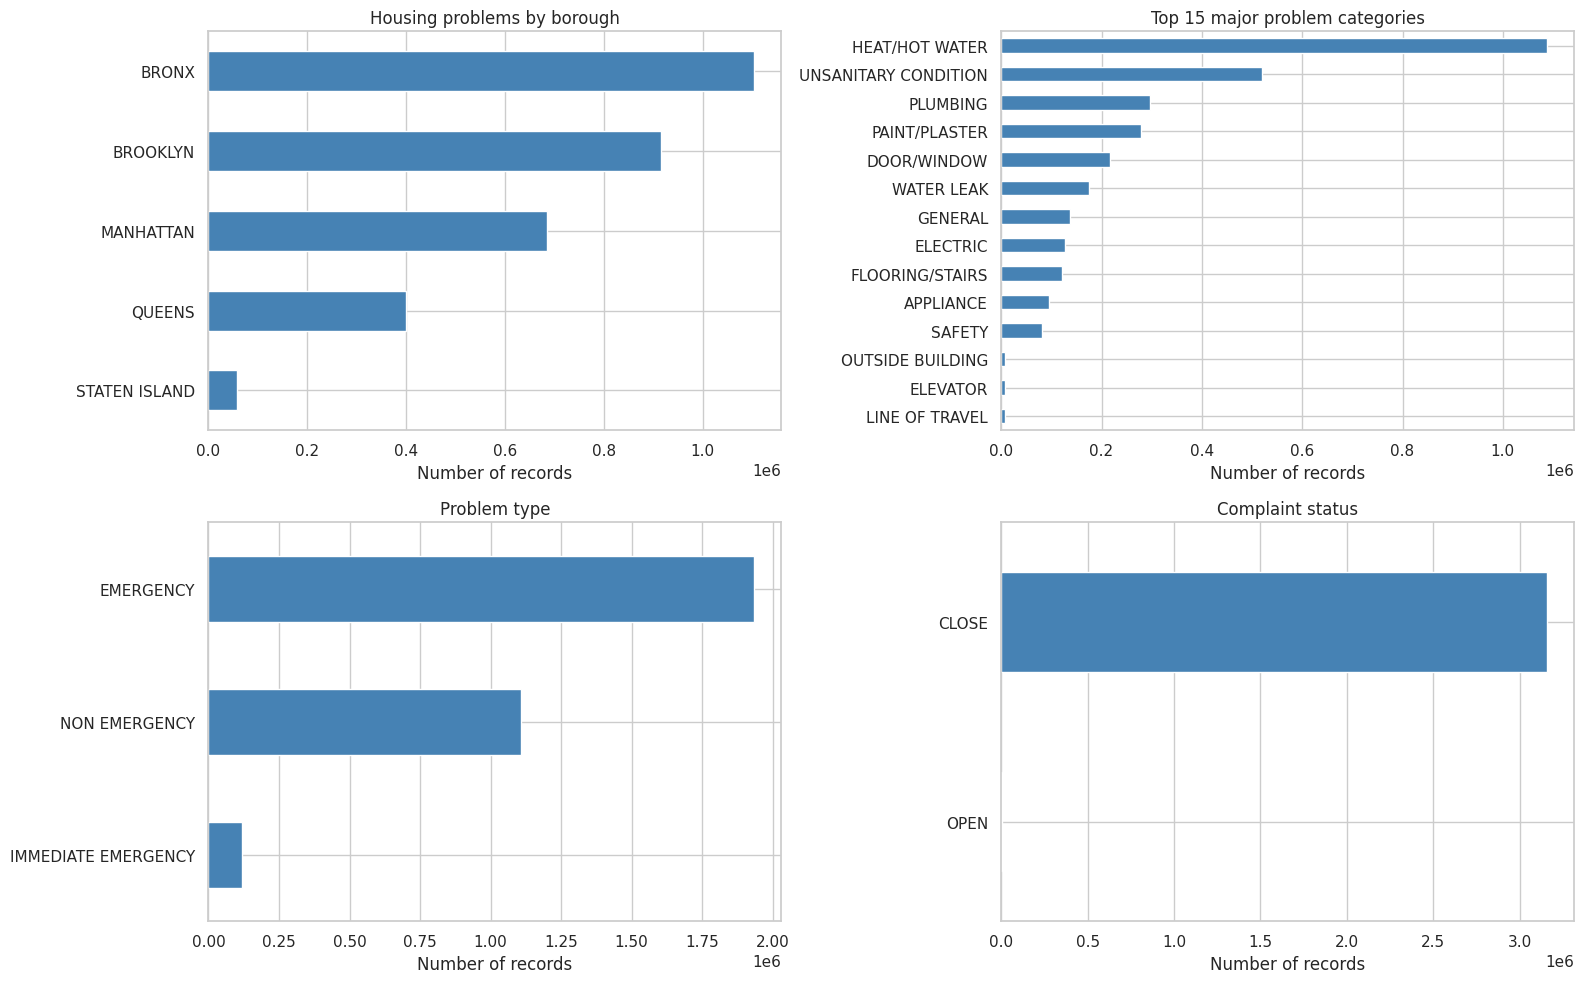

In [9]:
# ============================================================
# 2.5 Housing: categorical distributions
# ============================================================
print('Borough values (checking for inconsistent spellings):')
print(df_housing['borough'].value_counts(dropna=False))

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
plot_top_counts(df_housing['borough'],          'Housing problems by borough',     ax=axes[0, 0])
plot_top_counts(df_housing['major_category'],   'Top 15 major problem categories', ax=axes[0, 1])
plot_top_counts(df_housing['type'],             'Problem type',                    ax=axes[1, 0])
plot_top_counts(df_housing['complaint_status'], 'Complaint status',                ax=axes[1, 1])
plt.tight_layout()
plt.show()

Housing problems per month (2022–2025): 0 unparseable or missing dates


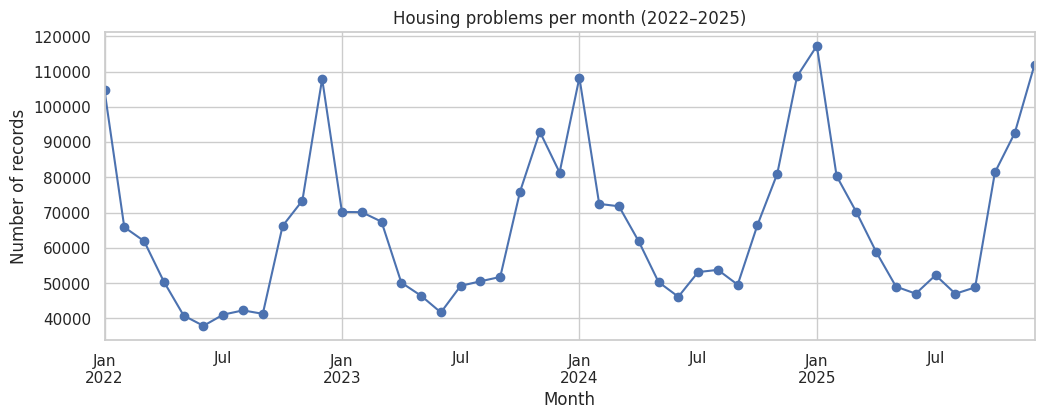

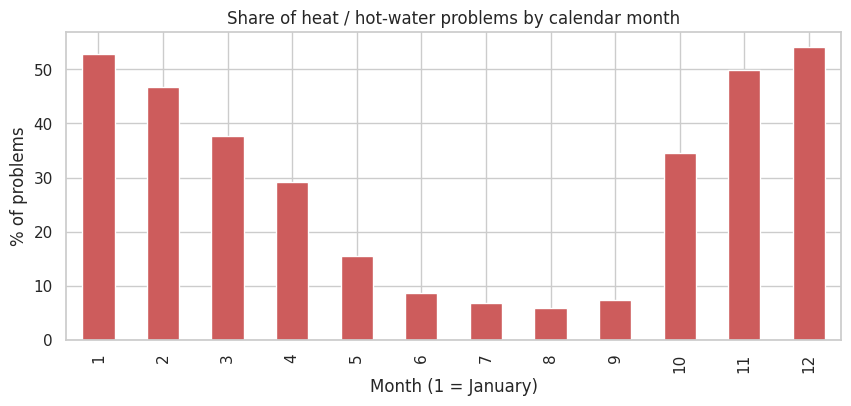

Problems per year:
received_date
2022    733471
2023    747466
2024    823169
2025    856280
Name: count, dtype: int64


In [10]:
# ============================================================
# 2.6 Housing: temporal patterns
# ============================================================
housing_dates = plot_monthly_counts(df_housing['received_date'], 'Housing problems per month (2022–2025)')
plt.show()

# Seasonality check: share of HEAT/HOT WATER problems per calendar month
is_heat = df_housing['major_category'].astype(str).str.upper().str.contains('HEAT')
heat_share = is_heat.groupby(housing_dates.dt.month).mean() * 100

ax = heat_share.plot.bar(figsize=(10, 4), color='indianred')
ax.set_title('Share of heat / hot-water problems by calendar month')
ax.set_xlabel('Month (1 = January)')
ax.set_ylabel('% of problems')
plt.show()

print('Problems per year:')
print(housing_dates.dt.year.value_counts().sort_index())

post_code dtype: float64
Missing ZIP: 3,287 | Outside 10001–11697: 199
Housing: missing coordinates = 663 (0.02%) | outside NYC = 0 (0.00%)

Sample community_board values: [11  8 12  7  4 10  9 14 16 17]
Unique community boards: 36


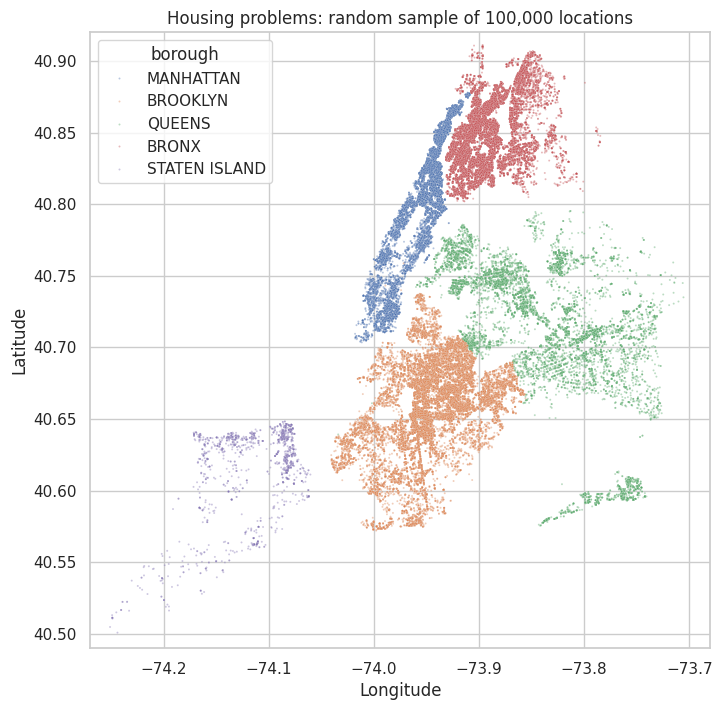

In [11]:
# ============================================================
# 2.7 Housing: geographic fields (ZIP, coordinates, community board)
# ============================================================
# ZIP codes: NYC ZIPs fall roughly between 10001 and 11697
housing_zip = pd.to_numeric(df_housing['post_code'], errors='coerce')
print(f"post_code dtype: {df_housing['post_code'].dtype}")
print(f'Missing ZIP: {housing_zip.isna().sum():,} | '
      f'Outside 10001–11697: {(~housing_zip.between(10001, 11697) & housing_zip.notna()).sum():,}')

# Coordinates
housing_lat, housing_lon = coordinate_check(df_housing, 'latitude', 'longitude', 'Housing')

# Community board format (needed to match the crash dataset later)
print('\nSample community_board values:', df_housing['community_board'].dropna().unique()[:10])
print(f"Unique community boards: {df_housing['community_board'].nunique()}")

# Map of a random sample of problems (plotting 3M+ points would be too slow)
sample_idx = df_housing.sample(100_000, random_state=42).index
fig, ax = plt.subplots(figsize=(8, 8))
sns.scatterplot(x=housing_lon[sample_idx], y=housing_lat[sample_idx],
                hue=df_housing.loc[sample_idx, 'borough'], s=2, alpha=0.4, ax=ax)
ax.set_xlim(NYC_LON)
ax.set_ylim(NYC_LAT)
ax.set_title('Housing problems: random sample of 100,000 locations')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.show()

## 2.3 Transportation Dataset: Structure and Missing Values

In [12]:
# ============================================================
# 2.9 Transport: structure, data types, missing values
# ============================================================
transport_summary = dataset_overview(df_transport, 'SIRTA Serious Crashes (2022–2025)')
display(transport_summary)
display(df_transport.head())

print('Duplicated open_data_crash_id values:',
      f"{df_transport['open_data_crash_id'].duplicated().sum():,}")

===== SIRTA Serious Crashes (2022–2025) =====
Rows: 11,958 | Columns: 23 | Memory: 6 MB
Fully duplicated rows: 0


,dtype,missing,missing_%,unique
highway_reference_marker,object,11000,91.99,760
bbl,float64,9891,82.71,1858
bin,float64,9891,82.71,1854
address,object,9690,81.03,2220
census_tract_2020_,float64,9202,76.95,1262
neighborhood_tabulation_area_nta_2020_,object,9202,76.95,221
council_district,float64,9202,76.95,51
community_board,float64,9202,76.95,68
zipcode,float64,4887,40.87,186
cross_street,object,4697,39.28,3107


,open_data_crash_id,crash_date,crash_time,crash_police_precinct,crash_borough,total_non_severe_injuries,total_severe_injuries,total_fatalities,latitude,longitude,on_street,cross_street,similar_fatalities_severe,similar_fatalities_all,address,community_board,council_district,bin,bbl,census_tract_2020_,neighborhood_tabulation_area_nta_2020_,highway_reference_marker,zipcode
0,4492364,2022-01-01T00:00:00.000,01:28,46,Bronx,1,1,0,40.858707,-73.90370,JEROME AVENUE,EAST 183 STREET,0.0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,4491159,2022-01-01T00:00:00.000,04:33,46,Bronx,0,1,0,NaN,NaN,JEROME AVENUE,NaN,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,4491487,2022-01-01T00:00:00.000,05:55,47,Bronx,0,1,0,40.871550,-73.86428,NaN,NaN,0.0,0,3207 WALLACE AVENUE,212.0,12.0,2056281.0,2.045980e+09,372.0,BX1201,NaN,NaN
3,4491223,2022-01-01T00:00:00.000,10:42,43,Bronx,0,1,0,40.823673,-73.87233,BRONX RIVER PARKWAY,NaN,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,907HX1M11001,NaN
4,4491418,2022-01-01T00:00:00.000,20:55,49,Bronx,0,1,0,40.863945,-73.86452,BOSTON ROAD,WALLACE AVENUE,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Duplicated open_data_crash_id values: 0


,total_non_severe_injuries,total_severe_injuries,total_fatalities
count,11958.00,11958.00,11958.00
mean,0.27,1.01,0.08
std,0.82,0.45,0.29
min,0.00,0.00,0.00
25%,0.00,1.00,0.00
50%,0.00,1.00,0.00
75%,0.00,1.00,0.00
max,19.00,7.00,5.00


total_non_severe_injuries: IQR bounds [0.0, 0.0] → 1,971 flagged | max = 19
total_severe_injuries: IQR bounds [1.0, 1.0] → 1,545 flagged | max = 7
total_fatalities: IQR bounds [0.0, 0.0] → 925 flagged | max = 5


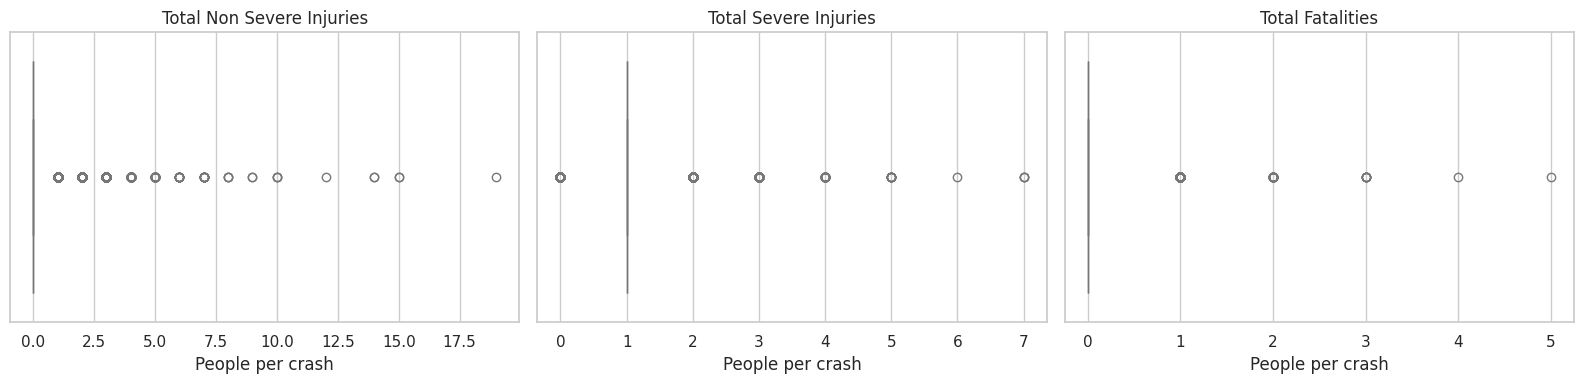

In [13]:
# ============================================================
# 2.10 Transport: injury and fatality distributions + outliers
# ============================================================
severity_cols = ['total_non_severe_injuries', 'total_severe_injuries', 'total_fatalities']
severity = df_transport[severity_cols].apply(pd.to_numeric, errors='coerce')

display(severity.describe().round(2))

# IQR check: with mostly 0/1 values the IQR can be 0, which would flag every non-zero
# value as an outlier, so the result is compared with a domain rule in the cleaning step
for col in severity_cols:
    n_out, low, high = iqr_bounds(severity[col])
    print(f'{col}: IQR bounds [{low:.1f}, {high:.1f}] → {n_out:,} flagged | max = {severity[col].max()}')

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, severity_cols):
    sns.boxplot(x=severity[col], ax=ax, color='lightsteelblue')
    ax.set_title(col.replace('_', ' ').title())
    ax.set_xlabel('People per crash')
plt.tight_layout()
plt.show()

crash_borough values:
crash_borough
Brooklyn         3557
Queens           2974
Manhattan        2448
Bronx            2365
Staten Island     578
NaN                36
Name: count, dtype: int64


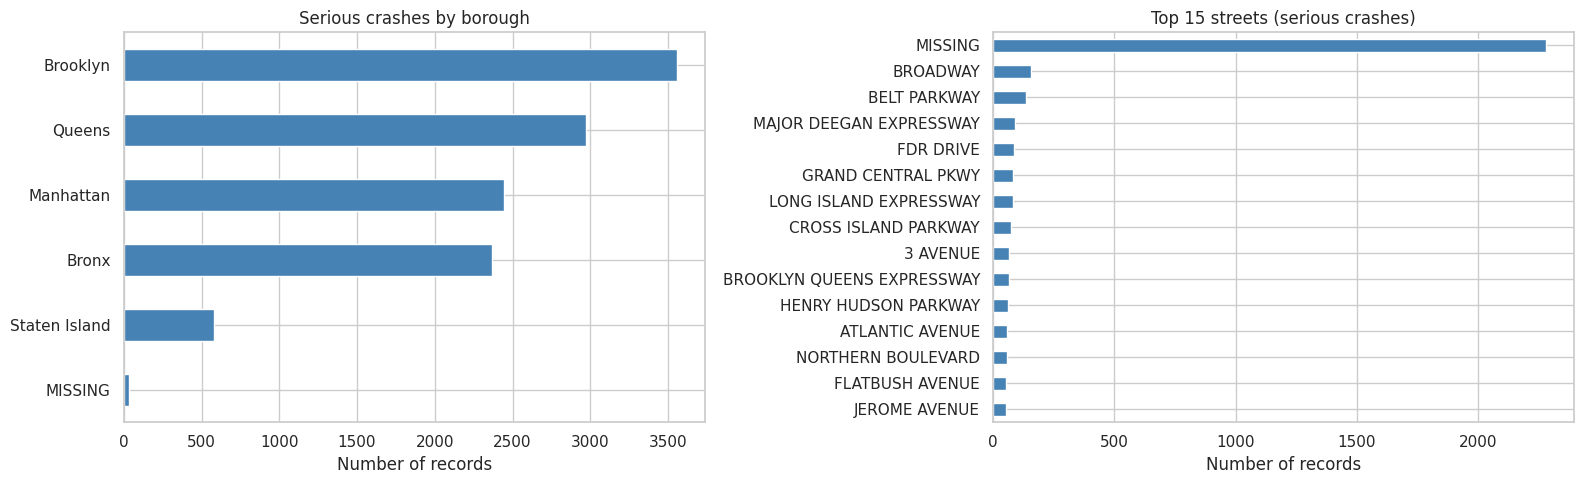

Serious crashes per month (2022–2025): 0 unparseable or missing dates


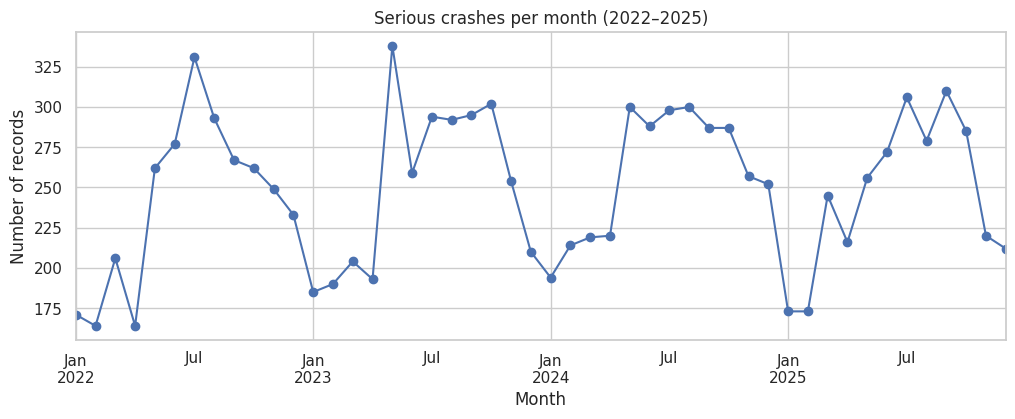

Unparseable crash_time values: 0


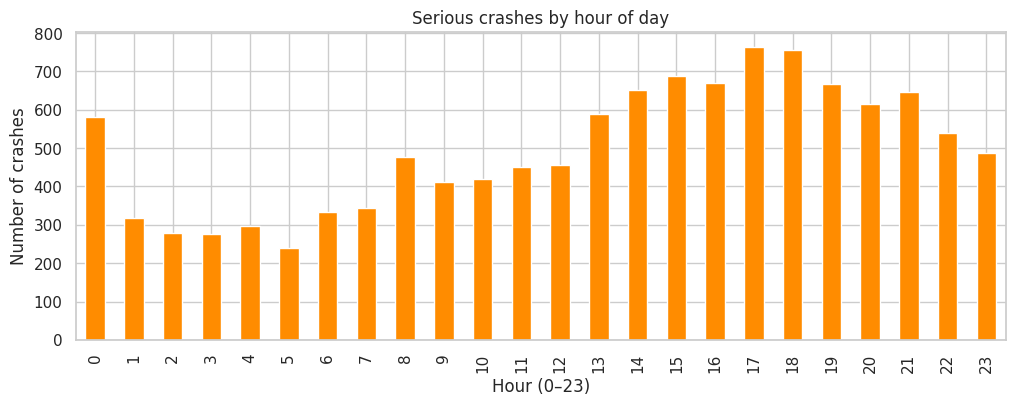

In [14]:
# ============================================================
# 2.11 Transport: boroughs, streets, time patterns
# ============================================================
print('crash_borough values:')
print(df_transport['crash_borough'].value_counts(dropna=False))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
plot_top_counts(df_transport['crash_borough'], 'Serious crashes by borough',      ax=axes[0])
plot_top_counts(df_transport['on_street'],     'Top 15 streets (serious crashes)', ax=axes[1])
plt.tight_layout()
plt.show()

crash_dates = plot_monthly_counts(df_transport['crash_date'], 'Serious crashes per month (2022–2025)')
plt.show()

# Hour of day: take the leading hour digits from crash_time (robust to small format differences)
crash_hour = pd.to_numeric(df_transport['crash_time'].astype(str).str.extract(r'^(\d{1,2})')[0],
                           errors='coerce')
print(f'Unparseable crash_time values: {crash_hour.isna().sum():,}')

ax = crash_hour.value_counts().sort_index().plot.bar(figsize=(12, 4), color='darkorange')
ax.set_title('Serious crashes by hour of day')
ax.set_xlabel('Hour (0–23)')
ax.set_ylabel('Number of crashes')
plt.show()

Transport: missing coordinates = 2,275 (19.02%) | outside NYC = 0 (0.00%)
Missing ZIP: 4,887 (40.87%)
  ...of which have coordinates (ZIP recoverable): 3,808
Outside 10001–11697: 36

Sample community_board values: [212. 201. 202. 209. 204. 208. 210. 203. 206. 303.]
Unique community boards: 68


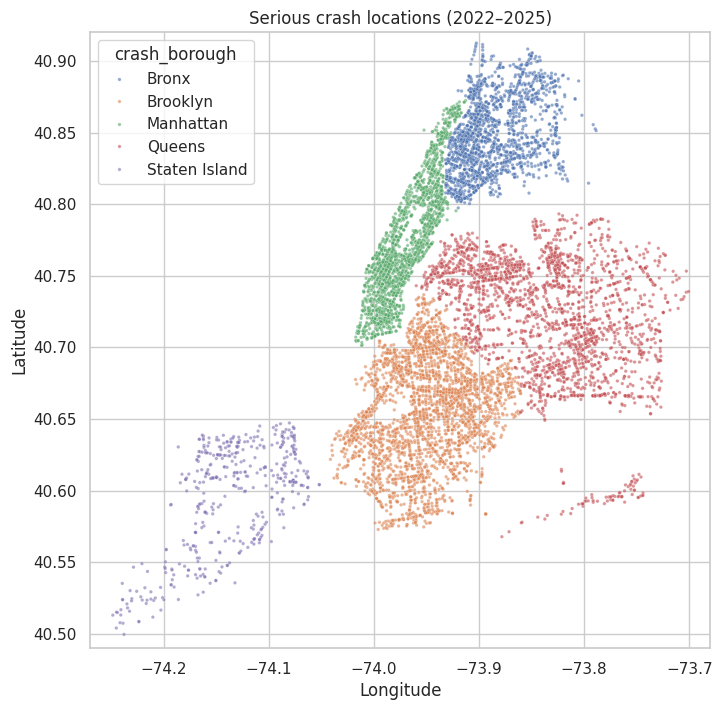

In [15]:
# ============================================================
# 2.12 Transport: geographic fields (ZIP, coordinates, community board)
# ============================================================
crash_zip = pd.to_numeric(df_transport['zipcode'], errors='coerce')
crash_lat, crash_lon = coordinate_check(df_transport, 'latitude', 'longitude', 'Transport')

missing_zip = crash_zip.isna()
has_coords  = crash_lat.notna() & crash_lon.notna()
print(f'Missing ZIP: {missing_zip.sum():,} ({missing_zip.mean():.2%})')
print(f'  ...of which have coordinates (ZIP recoverable): {(missing_zip & has_coords).sum():,}')
print(f'Outside 10001–11697: {(~crash_zip.between(10001, 11697) & crash_zip.notna()).sum():,}')

print('\nSample community_board values:', df_transport['community_board'].dropna().unique()[:10])
print(f"Unique community boards: {df_transport['community_board'].nunique()}")

fig, ax = plt.subplots(figsize=(8, 8))
sns.scatterplot(x=crash_lon, y=crash_lat, hue=df_transport['crash_borough'], s=6, alpha=0.6, ax=ax)
ax.set_xlim(NYC_LON)
ax.set_ylim(NYC_LAT)
ax.set_title('Serious crash locations (2022–2025)')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.show()

In [16]:
# ============================================================
# 2.13 Integration keys: are they in the same format in both datasets?
# ============================================================
key_pairs = {
    'Borough':         ('borough',         'crash_borough'),
    'ZIP code':        ('post_code',       'zipcode'),
    'Community board': ('community_board', 'community_board'),
    'Date':            ('received_date',   'crash_date'),
}

rows = []
for key, (h_col, t_col) in key_pairs.items():
    rows.append({
        'key':              key,
        'housing_column':   h_col,
        'housing_dtype':    str(df_housing[h_col].dtype),
        'housing_examples': list(df_housing[h_col].dropna().astype(str).unique()[:4]),
        'crash_column':     t_col,
        'crash_dtype':      str(df_transport[t_col].dtype),
        'crash_examples':   list(df_transport[t_col].dropna().astype(str).unique()[:4]),
    })

pd.set_option('display.max_colwidth', None)
display(pd.DataFrame(rows))

,key,housing_column,housing_dtype,housing_examples,crash_column,crash_dtype,crash_examples
0,Borough,borough,object,"[MANHATTAN, BROOKLYN, QUEENS, BRONX]",crash_borough,object,"[Bronx, Brooklyn, Manhattan, Queens]"
1,ZIP code,post_code,float64,"[10029.0, 10044.0, 10032.0, 10021.0]",zipcode,float64,"[10467.0, 10451.0, 10456.0, 10455.0]"
2,Community board,community_board,int64,"[11, 8, 12, 7]",community_board,float64,"[212.0, 201.0, 202.0, 209.0]"
3,Date,received_date,object,"[2022-01-16T00:54:39.000, 2022-01-23T22:05:21.000, 2022-02-04T13:40:22.000, 2022-02-11T12:58:54.000]",crash_date,object,"[2022-01-01T00:00:00.000, 2022-01-02T00:00:00.000, 2022-01-03T00:00:00.000, 2022-01-04T00:00:00.000]"


## 2.4 EDA Key Findings

### Housing (3,160,386 problems, 17 columns, 2.2 GB in memory)
- **Missing values:** very low. `post_code` 3,287 (0.10%), `latitude`/`longitude`/`nta` 663 (0.02%).
  All other columns are complete.
- **Duplicates:** 0 identical rows and 0 repeated `problem_id`, but **502,470 problems (15.9%) are
  flagged by HPD as duplicates** (`problem_duplicate_flag = Y`), meaning the same problem was reported again.
- **Structure:** 1,930,119 unique complaints, so on average **1.64 problems per complaint** (max 72).
  Counting rows means counting problems, not complaints.
- **Inconsistencies:** borough names are clean (5 values, all UPPER). `community_board` has 36 distinct
  values although no borough has more than 18 districts, so some codes are not real districts.
  It also stores only the local number (e.g. `12`), not the borough.
- **Invalid values:** 199 ZIP codes are outside the NYC range (10001–11697).
- **Geography:** 0 coordinates outside NYC.
- **Temporal:** problems grow every year (733k in 2022 → 856k in 2025). Heat/hot-water problems show
  a strong winter peak (see seasonality chart).
- **Distribution:** the Bronx has the most problems (1.10M), more than Brooklyn (0.92M) despite a
  smaller population.
- **Data types:** `received_date` is text, `post_code` is a float (`10029.0`).

### Transportation (11,958 serious crashes, 23 columns)
- **Missing values:** high in location fields. `community_board`, `council_district`, `nta`, `census_tract`
  76.95%; `address` 81%; `bbl`/`bin` 82.7%; `highway_reference_marker` 92%; **`zipcode` 40.87%**;
  `latitude`/`longitude` 19.02%; `crash_borough` 36 rows (0.3%).
- **Recoverable:** 3,808 of the 4,887 crashes without a ZIP still have coordinates.
- **Duplicates:** 0 identical rows, 0 repeated `open_data_crash_id`.
- **Outliers:** IQR fails here. Q1 = Q3 for every injury column, so the IQR is 0 and it flags 1,971 /
  1,545 / 925 normal crashes as outliers. Maximums (19 non-severe injuries, 7 severe, 5 deaths) are
  plausible for bus or multi-vehicle crashes. `total_severe_injuries` has a minimum of 0, so some records
  may have no severe injury and no fatality, which contradicts the dataset's scope.
- **Inconsistencies:** borough names in Title case (`Brooklyn`) vs UPPER in housing. `community_board` has
  68 distinct codes but NYC has only 59 districts.
- **Invalid values:** 36 ZIP codes outside the NYC range.
- **Geography:** 0 coordinates outside NYC.
- **Distribution:** Brooklyn has the most serious crashes (3,557); Staten Island the fewest (578).

### Integration keys
| Key | Housing | Crashes | Problem |
|---|---|---|---|
| Borough | `MANHATTAN` | `Manhattan` | different case |
| ZIP | `10029.0` (float) | `10467.0` (float), **41% missing** | float → 5-char string; recover missing |
| Community district | `12` (local number) | `212` (borough code + number), **77% missing** | different format; recover missing |
| Date | text | text | convert to datetime |

**Main consequence:** the crash location fields are too incomplete to join directly. Since 81% of crashes
have coordinates, and the housing data has 3.1M located points with known ZIP and district, we **assign
each crash the ZIP and district of its nearest housing location**, and validate this against crashes whose
ZIP is already known.

→ These findings define the cleaning steps in Section 3.

# 3. Pre-Integration Cleaning

Each step below fixes a problem found in the EDA (Section 2.4). Every action is recorded in a
**cleaning log** with its impact, shown as a summary table at the end.

**Order:** formats and types → duplicates → missing values → outliers. Formats come first so that
duplicate and missing checks compare values in the same format.

**Common key for integration:** the **community district ID** (`cd_id`), a 3-digit code
(borough code × 100 + district number, e.g. `212` = Bronx district 12). NYC has 59 districts:
Manhattan 101–112, Bronx 201–212, Brooklyn 301–318, Queens 401–414, Staten Island 501–503.

In [17]:
# ============================================================
# 3.1 Cleaning setup: lookup tables, helper functions, cleaning log
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

# Borough codes used by NYC community districts (e.g. 212 = Bronx district 12)
BOROUGH_CODE  = {'MANHATTAN': 1, 'BRONX': 2, 'BROOKLYN': 3, 'QUEENS': 4, 'STATEN ISLAND': 5}
CODE_BOROUGH  = {v: k for k, v in BOROUGH_CODE.items()}
MAX_DISTRICT  = {1: 12, 2: 12, 3: 18, 4: 14, 5: 3}   # 12 + 12 + 18 + 14 + 3 = 59 real districts
MAX_MATCH_M   = 500                                  # max distance for a nearest-neighbour match

cleaning_log = []   # one row per cleaning action, shown as a summary table at the end


def log_step(dataset, step, rows_before, rows_after, affected, decision):
    """Record a cleaning action so every decision is documented with its impact."""
    cleaning_log.append({'dataset': dataset, 'step': step, 'rows_before': rows_before,
                         'rows_after': rows_after, 'values_affected': affected, 'decision': decision})


def is_valid_cd(cd):
    """True only for the 59 real community districts (101–112, 201–212, 301–318, 401–414, 501–503)."""
    cd = pd.to_numeric(cd, errors='coerce')
    max_d = (cd // 100).map(MAX_DISTRICT)
    district = cd % 100
    return max_d.notna() & (district >= 1) & (district <= max_d)


def clean_zip(series):
    """Convert ZIP codes to 5-character strings; values outside the NYC range become missing."""
    z = pd.to_numeric(series, errors='coerce')
    z = z.where(z.between(10001, 11697))
    return z.astype('Int64').astype('string')


def to_xy(lat, lon):
    """Approximate lat/lon → metres (accurate enough at NYC's latitude for nearest-neighbour search)."""
    return np.column_stack([(np.asarray(lon, float) + 73.95) * 84_370,
                            (np.asarray(lat, float) - 40.70) * 111_320])


print('Setup ready')

Setup ready


## 3.2 Housing Cleaning

| Step | EDA finding | Decision | Justification |
|---|---|---|---|
| Formats | `received_date` is text; `post_code` is a float | Convert to datetime; ZIP → 5-char string | Needed for time aggregation and to match the crash ZIP format |
| Text | Mixed sources may contain extra spaces or case differences | Trim + UPPER case | One spelling per value, so groups and joins match |
| District ID | Board stored as local number only; 36 values but max 18 | Build `cd_id` = borough code × 100 + board; non-districts → missing | Same format as the crash data; codes outside the 59 districts are not residential districts |
| Invalid ZIP | 199 outside NYC range | Set to missing, then recover | A wrong ZIP is worse than a missing one |
| Duplicates | 502,470 problems flagged `Y` | **Drop** | The same problem reported again would inflate housing problem counts |
| Missing ZIP / district | 0.10% / invalid codes | Recover from the nearest housing location with known values (≤ 500 m) | Coordinates are 99.98% complete, so location is known even when the ZIP is not |
| Missing coordinates | 663 rows | **Keep** | They still have a district, so they count at district level; they are only left off maps |
| Outliers | Up to 72 problems per complaint; winter peaks | **Keep** | Real behaviour, not errors (see 3.6) |
| Memory | 2.2 GB | Convert repeated text to `category` | Makes later steps faster and avoids Colab crashes |

In [18]:
# ============================================================
# 3.3 Housing: standardize formats and data types
# ============================================================
h_rows = len(df_housing)
h_mem_before = df_housing.memory_usage(deep=True).sum() / 1e6

# Dates: text → datetime, plus year/month for aggregation
df_housing['received_date'] = pd.to_datetime(df_housing['received_date'], errors='coerce')
df_housing['year']  = df_housing['received_date'].dt.year
df_housing['month'] = df_housing['received_date'].dt.month

# Text columns: trim spaces and use one consistent case (UPPER)
text_cols = ['borough', 'type', 'space_type', 'unit_type', 'major_category', 'minor_category',
             'complaint_status', 'problem_status', 'problem_duplicate_flag', 'nta']
for col in text_cols:
    df_housing[col] = df_housing[col].astype('string').str.strip().str.upper()

# ZIP: float (10029.0) → 5-character string ('10029'); impossible ZIPs → missing
zip_missing_raw = df_housing['post_code'].isna().sum()
df_housing['zip_code'] = clean_zip(df_housing['post_code'])
zip_invalid = df_housing['zip_code'].isna().sum() - zip_missing_raw

# Community district: borough code × 100 + local board number → same 3-digit format as the crash data
df_housing['cd_id'] = df_housing['borough'].map(BOROUGH_CODE) * 100 + df_housing['community_board']
cd_invalid_mask = ~is_valid_cd(df_housing['cd_id'])
print('Raw community_board values that are not a real district:')
print(df_housing.loc[cd_invalid_mask, ['borough', 'community_board']].value_counts().head(15))
df_housing.loc[cd_invalid_mask, 'cd_id'] = np.nan
df_housing['cd_id'] = df_housing['cd_id'].astype('Int64')

log_step('Housing', 'Format dates', h_rows, h_rows, 0, 'received_date → datetime; year, month extracted')
log_step('Housing', 'Standardize text', h_rows, h_rows, len(text_cols), 'trimmed + UPPER case')
log_step('Housing', 'Invalid ZIP → missing', h_rows, h_rows, int(zip_invalid), 'outside 10001–11697')
log_step('Housing', 'Build community district ID', h_rows, h_rows, int(cd_invalid_mask.sum()),
         'borough code × 100 + board; non-district codes → missing')

print(f'\nInvalid ZIPs set to missing: {zip_invalid:,}')
print(f'Invalid community districts set to missing: {cd_invalid_mask.sum():,}')
print(f"Valid community districts: {df_housing['cd_id'].nunique()} (expected 59)")

Raw community_board values that are not a real district:
borough        community_board
BRONX          0                  111
BROOKLYN       30                 110
               32                  89
               86                  60
QUEENS         0                   34
STATEN ISLAND  0                   25
QUEENS         26                  23
               40                  22
MANHATTAN      64                  19
BRONX          20                  13
QUEENS         41                  12
BROOKLYN       55                  10
QUEENS         82                  10
BROOKLYN       48                  10
QUEENS         81                   8
Name: count, dtype: int64

Invalid ZIPs set to missing: 199
Invalid community districts set to missing: 578
Valid community districts: 59 (expected 59)


Identical rows removed: 0
Flagged duplicate problems removed: 502,470 (15.9%)
Rows: 3,160,386 → 2,657,916


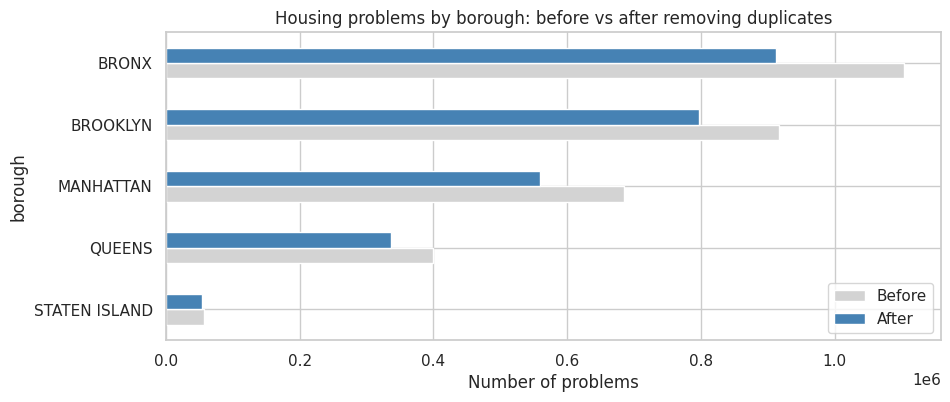

In [19]:
# ============================================================
# 3.4 Housing: duplicates
# ============================================================
before = len(df_housing)
borough_before = df_housing['borough'].value_counts()

# (a) Fully identical rows (EDA found 0; run anyway for completeness)
df_housing = df_housing.drop_duplicates()
after_exact = len(df_housing)

# (b) Problems flagged by HPD as duplicates of a problem already reported
dup_flag = df_housing['problem_duplicate_flag'].eq('Y')
df_housing = df_housing.loc[~dup_flag].reset_index(drop=True)

log_step('Housing', 'Drop identical rows', before, after_exact, before - after_exact, 'exact copies')
log_step('Housing', 'Drop HPD-flagged duplicates', after_exact, len(df_housing), int(dup_flag.sum()),
         'problem_duplicate_flag = Y (same problem reported again)')
print(f'Identical rows removed: {before - after_exact:,}')
print(f'Flagged duplicate problems removed: {dup_flag.sum():,} ({dup_flag.mean():.1%})')
print(f'Rows: {before:,} → {len(df_housing):,}')

# Before/after plot: duplicates by borough
borough_after = df_housing['borough'].value_counts()
comparison = pd.DataFrame({'Before': borough_before, 'After': borough_after})
ax = comparison.sort_values('Before').plot.barh(figsize=(10, 4), color=['lightgray', 'steelblue'])
ax.set_title('Housing problems by borough: before vs after removing duplicates')
ax.set_xlabel('Number of problems')
plt.show()

In [20]:
# ============================================================
# 3.5 Housing: missing values (recover ZIP and district from coordinates)
# ============================================================
# Reference points: housing locations where ZIP, district and coordinates are all known and valid.
# One row per unique location keeps the search fast.
ref = (df_housing.loc[df_housing['zip_code'].notna() & df_housing['cd_id'].notna()
                      & df_housing['latitude'].notna(),
                      ['latitude', 'longitude', 'zip_code', 'cd_id', 'borough']]
       .drop_duplicates(['latitude', 'longitude'])
       .reset_index(drop=True))
tree = cKDTree(to_xy(ref['latitude'], ref['longitude']))
print(f'Reference locations: {len(ref):,}')


def nearest_location(lat, lon, max_m=MAX_MATCH_M):
    """For each point, return ZIP, district and borough of the nearest reference location within max_m."""
    dist, idx = tree.query(to_xy(lat, lon))
    match = ref.loc[idx, ['zip_code', 'cd_id', 'borough']].reset_index(drop=True)
    match['distance_m'] = dist
    match.loc[dist > max_m, ['zip_code', 'cd_id', 'borough']] = pd.NA
    return match


missing_before = df_housing[['zip_code', 'cd_id', 'latitude']].isna().sum()

for key in ['zip_code', 'cd_id']:
    fill_mask = df_housing[key].isna() & df_housing['latitude'].notna()
    if fill_mask.any():
        match = nearest_location(df_housing.loc[fill_mask, 'latitude'],
                                 df_housing.loc[fill_mask, 'longitude'])
        df_housing.loc[fill_mask, key] = match[key].to_numpy()
    log_step('Housing', f'Recover {key} from coordinates', len(df_housing), len(df_housing),
             int(fill_mask.sum()), f'nearest housing location within {MAX_MATCH_M} m')

missing_after = df_housing[['zip_code', 'cd_id', 'latitude']].isna().sum()
display(pd.DataFrame({'missing_before': missing_before, 'missing_after': missing_after}))

# Rows still without a district cannot be integrated → drop (tiny share)
no_cd = df_housing['cd_id'].isna()
before = len(df_housing)
df_housing = df_housing.loc[~no_cd].reset_index(drop=True)
log_step('Housing', 'Drop rows with no district', before, len(df_housing), int(no_cd.sum()),
         'cannot be assigned to an integration unit')
print(f'Rows dropped (no district): {no_cd.sum():,}')
# Rows with missing coordinates but a valid district are KEPT: they still count at district level

Reference locations: 118,142


,missing_before,missing_after
zip_code,3214,230
cd_id,452,1
latitude,633,633


Rows dropped (no district): 1


Coordinates outside NYC: 0
Problems per complaint: IQR bounds [-0.5, 3.5] → 175,361 complaints flagged (12.0%) | max = 72


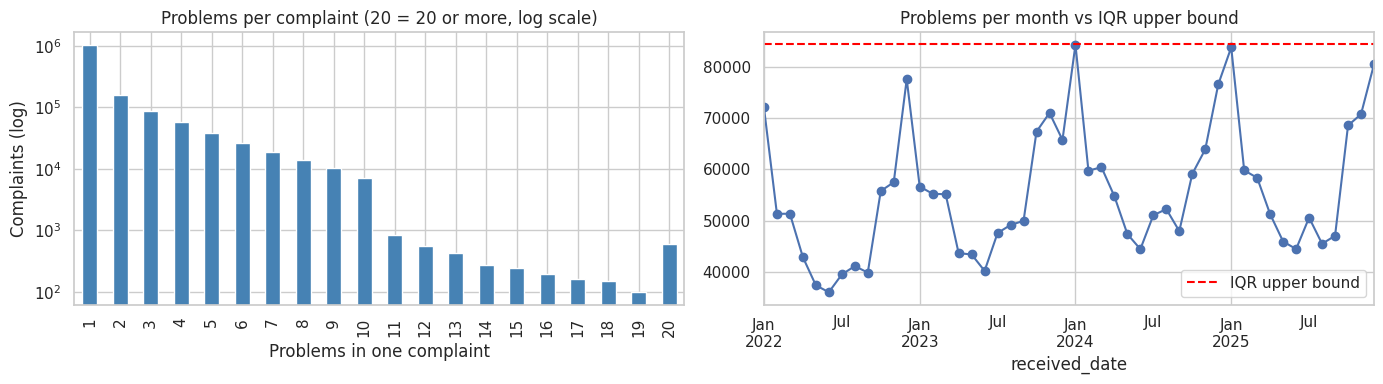

Months above the IQR bound: 0


In [21]:
# ============================================================
# 3.6 Housing: outliers
# ============================================================
# (a) Coordinates: domain rule = must be inside the NYC bounding box
lat = df_housing['latitude']
lon = df_housing['longitude']
outside = lat.notna() & ~(lat.between(*NYC_LAT) & lon.between(*NYC_LON))
print(f'Coordinates outside NYC: {outside.sum():,}')

# (b) Problems per complaint: IQR vs domain knowledge
ppc = df_housing.groupby('complaint_id').size()
n_out, low, high = iqr_bounds(ppc)
print(f'Problems per complaint: IQR bounds [{low:.1f}, {high:.1f}] → {n_out:,} complaints flagged '
      f'({n_out / len(ppc):.1%}) | max = {ppc.max()}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
ppc.clip(upper=20).value_counts().sort_index().plot.bar(ax=axes[0], color='steelblue', logy=True)
axes[0].set_title('Problems per complaint (20 = 20 or more, log scale)')
axes[0].set_xlabel('Problems in one complaint')
axes[0].set_ylabel('Complaints (log)')

# (c) Monthly volume: IQR on monthly counts
monthly = df_housing.groupby(df_housing['received_date'].dt.to_period('M')).size()
m_out, m_low, m_high = iqr_bounds(monthly)
monthly.plot(ax=axes[1], marker='o')
axes[1].axhline(m_high, color='red', linestyle='--', label='IQR upper bound')
axes[1].set_title('Problems per month vs IQR upper bound')
axes[1].legend()
plt.tight_layout()
plt.show()
print(f'Months above the IQR bound: {m_out}')

log_step('Housing', 'Outliers: coordinates', len(df_housing), len(df_housing), int(outside.sum()),
         'none outside NYC → nothing removed')
log_step('Housing', 'Outliers: problems per complaint', len(df_housing), len(df_housing), int(n_out),
         'kept: multi-problem complaints are real (one call can list many problems)')
log_step('Housing', 'Outliers: monthly volume', len(df_housing), len(df_housing), int(m_out),
         'kept: winter peaks are real heating-season demand')

In [22]:
# ============================================================
# 3.7 Housing: drop replaced columns and reduce memory
# ============================================================
df_housing = df_housing.drop(columns=['post_code', 'community_board'])   # replaced by zip_code, cd_id

low_cardinality = ['borough', 'type', 'space_type', 'unit_type', 'major_category', 'minor_category',
                   'complaint_status', 'problem_status', 'problem_duplicate_flag', 'nta', 'zip_code']
df_housing[low_cardinality] = df_housing[low_cardinality].astype('category')
df_housing['year']  = df_housing['year'].astype('int16')
df_housing['month'] = df_housing['month'].astype('int8')

h_mem_after = df_housing.memory_usage(deep=True).sum() / 1e6
log_step('Housing', 'Drop replaced columns + categories', len(df_housing), len(df_housing), 2,
         f'memory {h_mem_before:,.0f} MB → {h_mem_after:,.0f} MB')
print(f'Memory: {h_mem_before:,.0f} MB → {h_mem_after:,.0f} MB')
print(df_housing.dtypes)

Memory: 2,226 MB → 173 MB
received_date             datetime64[ns]
problem_id                         int64
complaint_id                       int64
borough                         category
unit_type                       category
space_type                      category
type                            category
major_category                  category
minor_category                  category
complaint_status                category
problem_status                  category
problem_duplicate_flag          category
latitude                         float64
longitude                        float64
nta                             category
year                               int16
month                               int8
zip_code                        category
cd_id                              Int64
dtype: object


## 3.3 Transportation Cleaning

| Step | EDA finding | Decision | Justification |
|---|---|---|---|
| Formats | Dates and times are text; borough in Title case | Datetime + year/month/weekday/hour; UPPER borough | Same format as housing; time features for research questions |
| District ID | 68 codes, only 59 real districts | Codes outside the 59 → missing, then recover | Extra codes are not residential districts |
| Unusable columns | 77–92% missing (`highway_reference_marker`, `bbl`, `bin`, `address`, `census_tract`, `nta`, `council_district`); `similar_fatalities_*` undocumented | **Drop** | Too empty to impute reliably and not needed; location is recovered from coordinates instead |
| Duplicates | 0 by ID | Also check same date + hour + location + injuries | Catches one crash recorded twice under two IDs |
| Missing ZIP (41%), district (77%), borough (0.3%) | 81% have coordinates | Nearest housing location (≤ 500 m), **validated** against crashes with a known ZIP; then ZIP → district; then district → borough | Recovers location without inventing values; original values are never overwritten |
| No location at all | Remaining rows | **Keep** with `in_integration = False` | Still valid for borough/time charts, excluded only from district-level integration |
| Outliers | IQR = 0 → flags normal crashes | Do not use IQR; use domain rules | IQR is not meaningful for count data that is almost always 0 or 1 |
| Non-serious records | Severe injuries can be 0 | **Drop** records with no severe injury **and** no fatality | They contradict the dataset's scope (serious crashes only) |
| Multi-victim crashes | Max 19 injured | **Keep** | Plausible real events (bus or multi-vehicle crashes) |

In [23]:
# ============================================================
# 3.9 Transport: standardize formats, data types, drop unusable columns
# ============================================================
t_rows = len(df_transport)

# Dates and times
df_transport['crash_date'] = pd.to_datetime(df_transport['crash_date'], errors='coerce')
df_transport['year']    = df_transport['crash_date'].dt.year
df_transport['month']   = df_transport['crash_date'].dt.month
df_transport['weekday'] = df_transport['crash_date'].dt.day_name()
df_transport['crash_hour'] = pd.to_numeric(
    df_transport['crash_time'].astype(str).str.extract(r'^(\d{1,2})')[0], errors='coerce')

# Text: same UPPER format as the housing data ('Brooklyn' → 'BROOKLYN')
for col in ['crash_borough', 'on_street', 'cross_street']:
    df_transport[col] = df_transport[col].astype('string').str.strip().str.upper()
df_transport = df_transport.rename(columns={'crash_borough': 'borough'})

# Geography keys in the same format as housing
zip_missing_raw = df_transport['zipcode'].isna().sum()
df_transport['zip_code'] = clean_zip(df_transport['zipcode'])
t_zip_invalid = df_transport['zip_code'].isna().sum() - zip_missing_raw

cd_raw = pd.to_numeric(df_transport['community_board'], errors='coerce')
t_cd_invalid = (cd_raw.notna() & ~is_valid_cd(cd_raw))
print('Crash community_board codes that are not one of the 59 districts:')
print(cd_raw[t_cd_invalid].value_counts())
df_transport['cd_id'] = cd_raw.where(is_valid_cd(cd_raw)).astype('Int64')

# Columns that are mostly empty and not needed for any research question
drop_cols = ['highway_reference_marker', 'bbl', 'bin', 'address', 'census_tract_2020_',
             'neighborhood_tabulation_area_nta_2020_', 'council_district',
             'similar_fatalities_severe', 'similar_fatalities_all',
             'zipcode', 'community_board', 'crash_time']
missing_share = df_transport[drop_cols].isna().mean().mul(100).round(1)
df_transport = df_transport.drop(columns=drop_cols)
print('\nDropped columns (% missing):')
print(missing_share)

log_step('Transport', 'Format dates/times', t_rows, t_rows, 0, 'crash_date → datetime; year, month, weekday, hour')
log_step('Transport', 'Standardize text', t_rows, t_rows, 3, 'trimmed + UPPER case; crash_borough → borough')
log_step('Transport', 'Invalid ZIP → missing', t_rows, t_rows, int(t_zip_invalid), 'outside 10001–11697')
log_step('Transport', 'Non-district CD codes → missing', t_rows, t_rows, int(t_cd_invalid.sum()),
         'codes outside the 59 districts')
log_step('Transport', 'Drop unusable columns', t_rows, t_rows, len(drop_cols),
         'mostly empty / replaced / not used in research questions')
print(f'\nInvalid ZIPs set to missing: {t_zip_invalid:,}')

Crash community_board codes that are not one of the 59 districts:
community_board
164.0    35
481.0     9
355.0     8
228.0     4
226.0     4
227.0     3
482.0     3
356.0     2
480.0     2
Name: count, dtype: int64

Dropped columns (% missing):
highway_reference_marker                  92.0
bbl                                       82.7
bin                                       82.7
address                                   81.0
census_tract_2020_                        77.0
neighborhood_tabulation_area_nta_2020_    77.0
council_district                          77.0
similar_fatalities_severe                 11.6
similar_fatalities_all                     0.0
zipcode                                   40.9
community_board                           77.0
crash_time                                 0.0
dtype: float64

Invalid ZIPs set to missing: 36


In [24]:
# ============================================================
# 3.10 Transport: duplicates
# ============================================================
before = len(df_transport)
df_transport = df_transport.drop_duplicates(subset='open_data_crash_id')

# Same crash recorded twice under different IDs: same date, hour, location and injuries
same_event = ['crash_date', 'crash_hour', 'latitude', 'longitude', 'on_street',
              'total_non_severe_injuries', 'total_severe_injuries', 'total_fatalities']
has_location = df_transport['latitude'].notna()
dup_event = has_location & df_transport.duplicated(subset=same_event, keep='first')
print(f'Possible double records (same date, hour, location, injuries): {dup_event.sum():,}')
display(df_transport.loc[df_transport.duplicated(subset=same_event, keep=False) & has_location]
        .sort_values(same_event).head(10))
df_transport = df_transport.loc[~dup_event].reset_index(drop=True)

log_step('Transport', 'Drop duplicate events', before, len(df_transport), before - len(df_transport),
         'same ID, or same date + hour + coordinates + injuries')
print(f'Rows: {before:,} → {len(df_transport):,}')

Possible double records (same date, hour, location, injuries): 5


,open_data_crash_id,crash_date,crash_police_precinct,borough,total_non_severe_injuries,total_severe_injuries,total_fatalities,latitude,longitude,on_street,cross_street,year,month,weekday,crash_hour,zip_code,cd_id
799,4532543,2022-05-30,78,BROOKLYN,0,1,0,40.653190,-73.966220,PARKSIDE AVENUE,PARADE PLACE,2022,5,Monday,16,<NA>,<NA>
800,4535113,2022-05-30,70,BROOKLYN,0,1,0,40.653190,-73.966220,PARKSIDE AVENUE,PARADE PLACE,2022,5,Monday,16,<NA>,<NA>
1871,4567373,2022-09-25,7,MANHATTAN,0,2,0,40.710697,-73.984634,<NA>,<NA>,2022,9,Sunday,0,<NA>,103
1872,4568099,2022-09-25,7,MANHATTAN,0,2,0,40.710697,-73.984634,<NA>,<NA>,2022,9,Sunday,0,<NA>,103
3948,4633628,2023-05-07,18,MANHATTAN,0,1,0,40.764110,-73.988500,WEST 51 STREET,9 AVENUE,2023,5,Sunday,7,10019,<NA>
3964,4633990,2023-05-07,18,MANHATTAN,0,1,0,40.764110,-73.988500,WEST 51 STREET,<NA>,2023,5,Sunday,7,<NA>,<NA>
8845,4829959,2025-07-21,114,QUEENS,0,1,0,40.767963,-73.911680,25 AVE,STEINWAY ST,2025,7,Monday,1,11103,<NA>
8929,4832191,2025-07-21,114,QUEENS,0,1,0,40.767963,-73.911680,25 AVE,STEINWAY ST,2025,7,Monday,1,11103,<NA>
9253,4839841,2025-09-05,17,MANHATTAN,0,1,0,40.760006,-73.966520,<NA>,<NA>,2025,9,Friday,12,10022,106
9257,4839904,2025-09-05,17,MANHATTAN,0,1,0,40.760006,-73.966520,<NA>,<NA>,2025,9,Friday,12,10022,106


Rows: 11,958 → 11,953


Distance from crash to nearest housing location (metres):
count    9678.0
mean       56.0
std        91.0
min         0.0
25%        15.0
50%        30.0
75%        64.0
max      1972.0
Name: distance_m, dtype: float64
Beyond 500 m (left unmatched): 67
Validation – zip_code: 93.3% agreement on 5,852 crashes with a known value
Validation – cd_id: 91.4% agreement on 2,537 crashes with a known value


,missing_before,missing_after,before_%,after_%
borough,36,7,0.3,0.1
zip_code,4920,1161,41.2,9.7
cd_id,9269,1116,77.5,9.3


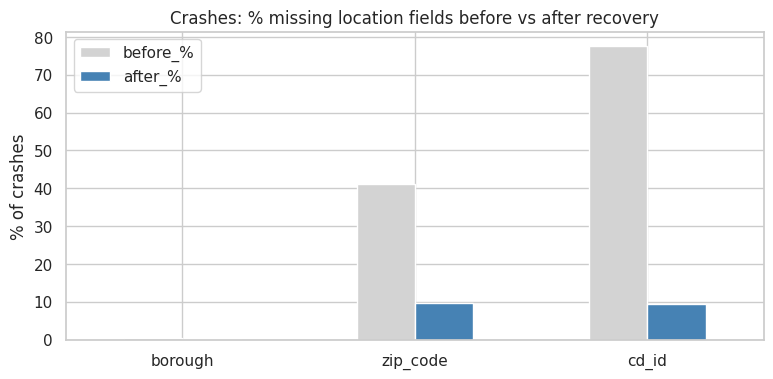

Crashes usable for district-level integration: 10,837 (90.7%)


In [25]:
# ============================================================
# 3.11 Transport: missing values (recover location from coordinates)
# ============================================================
geo_cols = ['borough', 'zip_code', 'cd_id']
missing_before = df_transport[geo_cols].isna().sum()

# --- Step 1: nearest housing location for every crash with coordinates ---
has_xy = df_transport['latitude'].notna() & df_transport['longitude'].notna()
match = nearest_location(df_transport.loc[has_xy, 'latitude'], df_transport.loc[has_xy, 'longitude'])
match.index = df_transport.index[has_xy]

print('Distance from crash to nearest housing location (metres):')
print(match['distance_m'].describe().round(0))
print(f"Beyond {MAX_MATCH_M} m (left unmatched): {(match['distance_m'] > MAX_MATCH_M).sum():,}")

# --- Step 2: validate the method on crashes that already have a ZIP / district ---
for key in ['zip_code', 'cd_id']:
    both = df_transport.loc[has_xy, key].notna() & match[key].notna()
    agree = (df_transport.loc[has_xy, key][both].astype(str) == match.loc[both, key].astype(str)).mean()
    print(f'Validation – {key}: {agree:.1%} agreement on {both.sum():,} crashes with a known value')

# --- Step 3: fill only values that are missing (original values always win) ---
for key in geo_cols:
    fill = has_xy & df_transport[key].isna()
    df_transport.loc[fill, key] = match.loc[fill[fill].index, key].to_numpy()
    log_step('Transport', f'Recover {key} from coordinates', len(df_transport), len(df_transport),
             int(fill.sum()), f'nearest housing location within {MAX_MATCH_M} m')

# --- Step 4: crashes with a ZIP but no coordinates → most common district of that ZIP ---
zip_to_cd = ref.groupby('zip_code', observed=True)['cd_id'].agg(lambda s: s.mode().iloc[0])
fill = df_transport['cd_id'].isna() & df_transport['zip_code'].notna()
df_transport.loc[fill, 'cd_id'] = df_transport.loc[fill, 'zip_code'].map(zip_to_cd)
log_step('Transport', 'Recover cd_id from ZIP', len(df_transport), len(df_transport), int(fill.sum()),
         'most common district of that ZIP in the housing data')

# --- Step 5: borough from district code if still missing ---
fill = df_transport['borough'].isna() & df_transport['cd_id'].notna()
df_transport.loc[fill, 'borough'] = (df_transport.loc[fill, 'cd_id'] // 100).map(CODE_BOROUGH)

missing_after = df_transport[geo_cols].isna().sum()
summary = pd.DataFrame({'missing_before': missing_before, 'missing_after': missing_after})
summary['before_%'] = (summary['missing_before'] / len(df_transport) * 100).round(1)
summary['after_%']  = (summary['missing_after']  / len(df_transport) * 100).round(1)
display(summary)

# Before/after plot
ax = summary[['before_%', 'after_%']].plot.bar(figsize=(9, 4), color=['lightgray', 'steelblue'], rot=0)
ax.set_title('Crashes: % missing location fields before vs after recovery')
ax.set_ylabel('% of crashes')
plt.show()

# Crashes with no usable location: kept, but flagged (usable for borough/time charts only)
df_transport['in_integration'] = df_transport['cd_id'].notna()
print(f"Crashes usable for district-level integration: {df_transport['in_integration'].sum():,} "
      f"({df_transport['in_integration'].mean():.1%})")

total_non_severe_injuries: IQR bounds [0, 0] → 1,971 flagged (16.5%)
total_severe_injuries: IQR bounds [1, 1] → 1,544 flagged (12.9%)
total_fatalities: IQR bounds [0, 0] → 925 flagged (7.7%)

Records with no severe injury and no fatality: 0


,crash_date,borough,total_non_severe_injuries,total_severe_injuries,total_fatalities



Largest crashes by number of victims:


,crash_date,borough,on_street,total_non_severe_injuries,total_severe_injuries,total_fatalities
2426,2023-01-02,MANHATTAN,BROADWAY,19,2,0
6673,2024-10-21,BROOKLYN,OCEAN PARKWAY,15,2,0
3940,2023-05-28,BROOKLYN,ESSEX STREET,15,0,1
5519,2024-02-27,BROOKLYN,<NA>,14,1,0
9441,2025-08-04,BROOKLYN,FRANKLIN AVE,14,1,0


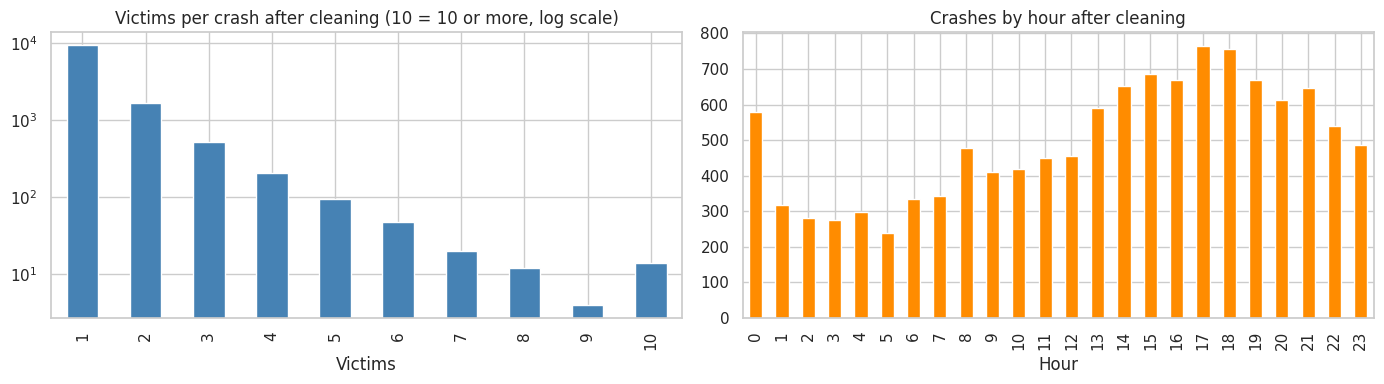

In [26]:
# ============================================================
# 3.12 Transport: outliers and inconsistent records
# ============================================================
severity_cols = ['total_non_severe_injuries', 'total_severe_injuries', 'total_fatalities']

# (a) IQR rule: Q1 = Q3 for every column, so the IQR is 0 and every non-typical value is "an outlier"
for col in severity_cols:
    n_out, low, high = iqr_bounds(df_transport[col])
    print(f'{col}: IQR bounds [{low:.0f}, {high:.0f}] → {n_out:,} flagged ({n_out / len(df_transport):.1%})')

# (b) Domain rule 1: this dataset contains serious crashes only, so every record
#     should have at least one severe injury or fatality
not_serious = (df_transport['total_severe_injuries'] == 0) & (df_transport['total_fatalities'] == 0)
print(f'\nRecords with no severe injury and no fatality: {not_serious.sum():,}')
display(df_transport.loc[not_serious, ['crash_date', 'borough'] + severity_cols].head())

# (c) Domain rule 2: very large crashes – inspect for plausibility instead of deleting
df_transport['total_victims'] = df_transport[severity_cols].sum(axis=1)
print('\nLargest crashes by number of victims:')
display(df_transport.nlargest(5, 'total_victims')[['crash_date', 'borough', 'on_street'] + severity_cols])

before = len(df_transport)
df_transport = df_transport.loc[~not_serious].reset_index(drop=True)

log_step('Transport', 'Outliers: IQR on injuries', before, before, 0,
         'IQR = 0 on 0/1 data → rule not meaningful, nothing removed')
log_step('Transport', 'Drop non-serious records', before, len(df_transport), int(not_serious.sum()),
         'contradict dataset scope (no severe injury, no fatality)')
log_step('Transport', 'Outliers: multi-victim crashes', len(df_transport), len(df_transport), 0,
         'kept: real events (e.g. bus or multi-vehicle crashes)')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df_transport['total_victims'].clip(upper=10).value_counts().sort_index().plot.bar(
    ax=axes[0], color='steelblue', logy=True)
axes[0].set_title('Victims per crash after cleaning (10 = 10 or more, log scale)')
axes[0].set_xlabel('Victims')
df_transport['crash_hour'].value_counts().sort_index().plot.bar(ax=axes[1], color='darkorange')
axes[1].set_title('Crashes by hour after cleaning')
axes[1].set_xlabel('Hour')
plt.tight_layout()
plt.show()

In [27]:
# ============================================================
# 3.13 Cleaning summary + save cleaned data
# ============================================================
df_transport[['borough', 'zip_code', 'weekday']] = df_transport[['borough', 'zip_code', 'weekday']].astype('category')

display(pd.DataFrame(cleaning_log))

print(f'Housing clean:   {df_housing.shape[0]:,} rows × {df_housing.shape[1]} columns')
print(f'Transport clean: {df_transport.shape[0]:,} rows × {df_transport.shape[1]} columns')

# Parquet keeps data types and is much smaller/faster than CSV
df_housing.to_parquet(f'{SAVE_DIR}/housing_clean.parquet', index=False)
df_transport.to_parquet(f'{SAVE_DIR}/transport_clean.parquet', index=False)
print('Saved housing_clean.parquet and transport_clean.parquet to Drive')

,dataset,step,rows_before,rows_after,values_affected,decision
0,Housing,Format dates,3160386,3160386,0,"received_date → datetime; year, month extracted"
1,Housing,Standardize text,3160386,3160386,10,trimmed + UPPER case
2,Housing,Invalid ZIP → missing,3160386,3160386,199,outside 10001–11697
3,Housing,Build community district ID,3160386,3160386,578,borough code × 100 + board; non-district codes → missing
4,Housing,Drop identical rows,3160386,3160386,0,exact copies
5,Housing,Drop HPD-flagged duplicates,3160386,2657916,502470,problem_duplicate_flag = Y (same problem reported again)
6,Housing,Recover zip_code from coordinates,2657916,2657916,2984,nearest housing location within 500 m
7,Housing,Recover cd_id from coordinates,2657916,2657916,451,nearest housing location within 500 m
8,Housing,Drop rows with no district,2657916,2657915,1,cannot be assigned to an integration unit
9,Housing,Outliers: coordinates,2657915,2657915,0,none outside NYC → nothing removed


Housing clean:   2,657,915 rows × 19 columns
Transport clean: 11,953 rows × 19 columns
Saved housing_clean.parquet and transport_clean.parquet to Drive


## 3.4 Cleaning Results

| Dataset | Before | After | Main changes |
|---|---|---|---|
| Housing | 3,160,386 rows, 2,226 MB | 2,657,915 rows, 173 MB | 502,470 HPD-flagged duplicates removed; 199 invalid ZIPs and 578 invalid district codes corrected |
| Crashes | 11,958 rows | 11,953 rows | 5 double records removed; location recovered for thousands of crashes |

**Location recovery for crashes:**

| Field | Missing before | Missing after |
|---|---|---|
| Community district | 9,269 (77.5%) | 1,116 (9.3%) |
| ZIP code | 4,920 (41.2%) | 1,161 (9.7%) |
| Borough | 36 (0.3%) | 7 (0.1%) |

**Validation of the recovery method:** on crashes where the true value was already known, the
nearest-location method gave the **same ZIP in 93.3%** of 5,852 cases and the **same district in 91.4%**
of 2,537 cases. The median distance from a crash to the nearest housing location is **30 m**; 67 crashes
farther than 500 m were left unmatched rather than guessed.

**Invalid housing district codes:** values such as `0`, `30`, `32`, `64` and `86` do not exist as NYC
community districts (max 18 per borough). They were set to missing and recovered from coordinates.

**Outliers:** IQR flagged 7–17% of crashes because injury counts are almost always 0 or 1 (IQR = 0), so
domain rules were used instead. **No record broke the dataset's scope** (0 crashes without a severe injury
or fatality). The largest crashes (e.g., 21 victims on Broadway, January 2023) are plausible multi-victim
events and were kept.

**Kept but flagged:** 1,116 crashes (9.3%) have no recoverable district. They remain in the data for
borough- and time-level charts (`in_integration = False`) but are excluded from district-level integration.

# 4. Data Integration

**Integration level: community district × year** (59 districts × 4 years = 236 rows).

| Level considered | Units | Serious crashes per unit | Decision |
|---|---|---|---|
| Borough × year | 20 | ~600 | ❌ Too coarse: only 5 places, hides neighbourhood differences |
| ZIP × year | ~180 × 4 | ~17 | ❌ Too sparse: many zeros, noisy |
| Row-to-row (crash ↔ complaint) | — | — | ❌ No real one-to-one relationship between a crash and a complaint |
| **Community district × year** | **236** | **~46** | ✅ Neighbourhood-level, enough crashes per unit, and an official NYC planning unit |

**Method:** each dataset is first **aggregated** to district × year, then the two tables are **merged on
`cd_id` + `year`**. A full grid of every district-year is built first, so a district-year with no crashes
appears as an explicit row instead of disappearing.

**Housing metrics:** problems, unique complaints, heat/hot-water problems, emergency problems, open
problems, and one count column per major category.
**Crash metrics:** crashes, fatal crashes, severe and non-severe injuries, fatalities, total victims,
night crashes (20:00–05:59) and weekend crashes.

In [28]:
# ============================================================
# 4.1 Aggregate housing to community district × year
# ============================================================
h = df_housing
h_type = h['type'].astype(str)

housing_flags = pd.DataFrame({
    'cd_id': h['cd_id'],
    'year':  h['year'],
    'complaint_id': h['complaint_id'],
    'is_heat':      h['major_category'].astype(str).str.contains('HEAT'),
    'is_emergency': h_type.str.contains('EMERGENCY') & ~h_type.str.startswith('NON'),
    'is_open':      h['problem_status'].astype(str).eq('OPEN'),
})

housing_agg = (housing_flags.groupby(['cd_id', 'year'])
               .agg(housing_problems=('complaint_id', 'size'),
                    housing_complaints=('complaint_id', 'nunique'),
                    heat_problems=('is_heat', 'sum'),
                    emergency_problems=('is_emergency', 'sum'),
                    open_problems=('is_open', 'sum'))
               .reset_index())

# One column per major category (used by the website's housing-category dropdown)
category_counts = (h.groupby(['cd_id', 'year', 'major_category'], observed=True).size()
                   .unstack(fill_value=0))
category_counts.columns = ['cat_' + c.lower().replace('/', '_').replace(' ', '_')
                           for c in category_counts.columns.astype(str)]
housing_agg = housing_agg.merge(category_counts.reset_index(), on=['cd_id', 'year'], how='left')

print(f'Housing aggregated: {housing_agg.shape[0]} rows × {housing_agg.shape[1]} columns')
print(f"Check: {housing_agg['housing_problems'].sum():,} problems = {len(df_housing):,} cleaned rows")
display(housing_agg.head())

Housing aggregated: 236 rows × 21 columns
Check: 2,657,915 problems = 2,657,915 cleaned rows


,cd_id,year,housing_problems,housing_complaints,heat_problems,emergency_problems,open_problems,cat_appliance,cat_door_window,cat_electric,cat_elevator,cat_flooring_stairs,cat_general,cat_heat_hot_water,cat_line_of_travel,cat_outside_building,cat_paint_plaster,cat_plumbing,cat_safety,cat_unsanitary_condition,cat_water_leak
0,101,2022,1579,715,273,990,0,114,117,88,19,96,129,273,0,9,88,157,115,268,106
1,101,2023,794,519,188,498,0,15,55,16,9,36,64,188,9,2,67,105,26,161,41
2,101,2024,919,568,204,564,0,32,66,58,5,40,58,204,0,2,79,111,21,186,57
3,101,2025,803,593,227,535,11,26,55,30,4,29,47,227,0,1,43,101,9,179,52
4,102,2022,3745,2488,1079,2272,0,89,319,136,14,125,261,1079,0,18,320,366,113,701,204


In [29]:
# ============================================================
# 4.2 Aggregate crashes to community district × year
# ============================================================
t = df_transport.loc[df_transport['in_integration']].copy()
t['is_night']   = (t['crash_hour'] >= 20) | (t['crash_hour'] < 6)
t['is_weekend'] = t['weekday'].astype(str).isin(['Saturday', 'Sunday'])
t['is_fatal']   = t['total_fatalities'] > 0

transport_agg = (t.groupby(['cd_id', 'year'])
                 .agg(crashes=('open_data_crash_id', 'size'),
                      fatal_crashes=('is_fatal', 'sum'),
                      severe_injuries=('total_severe_injuries', 'sum'),
                      non_severe_injuries=('total_non_severe_injuries', 'sum'),
                      fatalities=('total_fatalities', 'sum'),
                      total_victims=('total_victims', 'sum'),
                      night_crashes=('is_night', 'sum'),
                      weekend_crashes=('is_weekend', 'sum'))
                 .reset_index())

print(f'Transport aggregated: {transport_agg.shape[0]} rows × {transport_agg.shape[1]} columns')
print(f"Check: {transport_agg['crashes'].sum():,} crashes = {len(t):,} crashes with a district")
display(transport_agg.head())

Transport aggregated: 236 rows × 10 columns
Check: 10,837 crashes = 10,837 crashes with a district


,cd_id,year,crashes,fatal_crashes,severe_injuries,non_severe_injuries,fatalities,total_victims,night_crashes,weekend_crashes
0,101,2022,11,2,9,1,2,12,1,1
1,101,2023,13,0,13,0,0,13,3,4
2,101,2024,26,0,26,2,0,28,6,8
3,101,2025,23,0,24,2,0,26,7,7
4,102,2022,32,0,35,8,0,43,13,8


In [30]:
# ============================================================
# 4.3 Merge: full grid of 59 districts × 4 years, then join both datasets
# ============================================================
# A full grid makes "no crashes recorded" an explicit row instead of a silently missing one
all_cds = sorted(set(housing_agg['cd_id'].dropna().astype(int)) | set(transport_agg['cd_id'].dropna().astype(int)))
grid = pd.MultiIndex.from_product([all_cds, YEARS], names=['cd_id', 'year']).to_frame(index=False)

for df_ in (housing_agg, transport_agg):
    df_['cd_id'] = df_['cd_id'].astype(int)
    df_['year']  = df_['year'].astype(int)

df_integrated = (grid
                 .merge(housing_agg,   on=['cd_id', 'year'], how='left', indicator='housing_match')
                 .merge(transport_agg, on=['cd_id', 'year'], how='left', indicator='transport_match'))

print(f'Districts: {len(all_cds)} | Grid rows: {len(grid)} (= {len(all_cds)} × {len(YEARS)})')
print(f'Integrated: {df_integrated.shape[0]} rows × {df_integrated.shape[1]} columns')
print('\nRows with housing data:  ', df_integrated['housing_match'].value_counts().to_dict())
print('Rows with crash data:    ', df_integrated['transport_match'].value_counts().to_dict())
display(df_integrated.head())

Districts: 59 | Grid rows: 236 (= 59 × 4)
Integrated: 236 rows × 31 columns

Rows with housing data:   {'both': 236, 'left_only': 0, 'right_only': 0}
Rows with crash data:     {'both': 236, 'left_only': 0, 'right_only': 0}


,cd_id,year,housing_problems,housing_complaints,heat_problems,emergency_problems,open_problems,cat_appliance,cat_door_window,cat_electric,cat_elevator,cat_flooring_stairs,cat_general,cat_heat_hot_water,cat_line_of_travel,cat_outside_building,cat_paint_plaster,cat_plumbing,cat_safety,cat_unsanitary_condition,cat_water_leak,housing_match,crashes,fatal_crashes,severe_injuries,non_severe_injuries,fatalities,total_victims,night_crashes,weekend_crashes,transport_match
0,101,2022,1579,715,273,990,0,114,117,88,19,96,129,273,0,9,88,157,115,268,106,both,11,2,9,1,2,12,1,1,both
1,101,2023,794,519,188,498,0,15,55,16,9,36,64,188,9,2,67,105,26,161,41,both,13,0,13,0,0,13,3,4,both
2,101,2024,919,568,204,564,0,32,66,58,5,40,58,204,0,2,79,111,21,186,57,both,26,0,26,2,0,28,6,8,both
3,101,2025,803,593,227,535,11,26,55,30,4,29,47,227,0,1,43,101,9,179,52,both,23,0,24,2,0,26,7,7,both
4,102,2022,3745,2488,1079,2272,0,89,319,136,14,125,261,1079,0,18,320,366,113,701,204,both,32,0,35,8,0,43,13,8,both


# 5. Post-Integration Cleaning

Merging can create new problems that did not exist in either dataset alone:

| Problem | Cause | Decision | Justification |
|---|---|---|---|
| **New NaNs** | A district-year with housing problems but no serious crash has no crash row to join | Fill count columns with **0** | Both sources are complete for 2022–2025, so "no record" means zero events, not unknown |
| **Type mismatch** | Count columns become floats when NaNs appear (`3.0`) | Convert back to integers | Counts are whole numbers; needed for clean display on the website |
| **Redundant columns** | Each dataset has its own borough; a category column can equal another metric (e.g. `cat_heat_hot_water` = `heat_problems`) | One `borough` derived from `cd_id`; drop identical category columns | One source of truth per fact |
| **Consistency** | Recovered districts could fall in a different borough than recorded | Compare crash borough vs district borough | Confirms the recovery is consistent |
| **Undefined rates** | Dividing by zero crashes | Leave as NaN, not 0 | A rate of 0 would wrongly pull averages down |

Validation: totals of housing problems, crashes and fatalities must be **identical before and after** the merge.

In [31]:
# ============================================================
# 5.1 Post-integration: missing values created by the merge
# ============================================================
print('Missing values after merge:')
na_after_merge = df_integrated.isna().sum()
print(na_after_merge[na_after_merge > 0])

count_cols = [c for c in df_integrated.columns
              if c not in ('cd_id', 'year', 'housing_match', 'transport_match')]
filled = int(df_integrated[count_cols].isna().sum().sum())

# Both sources are complete for 2022–2025, so a district-year with no record had zero events
df_integrated[count_cols] = df_integrated[count_cols].fillna(0)
log_step('Integrated', 'Fill merge NaNs with 0', len(df_integrated), len(df_integrated), filled,
         'no record in a complete source = zero events')

df_integrated = df_integrated.drop(columns=['housing_match', 'transport_match'])
print(f'\nValues filled with 0: {filled:,}')
print('Remaining missing values:', int(df_integrated.isna().sum().sum()))

Missing values after merge:
Series([], dtype: int64)

Values filled with 0: 0
Remaining missing values: 0


In [32]:
# ============================================================
# 5.2 Post-integration: data types, readable labels, redundancy check
# ============================================================
# Counts become floats after a merge with NaNs → back to integers
df_integrated[count_cols] = df_integrated[count_cols].round().astype('int64')

# One borough column, derived from the key (instead of two borough columns from two sources)
df_integrated['borough']     = (df_integrated['cd_id'] // 100).map(CODE_BOROUGH)
df_integrated['district_no'] = df_integrated['cd_id'] % 100
df_integrated['cd_label']    = df_integrated['borough'].str.title() + ' CD ' + df_integrated['district_no'].astype(str)

# Redundancy check: the original crash borough must agree with the borough of the assigned district
t_check = df_transport.loc[df_transport['in_integration'], ['borough', 'cd_id']].copy()
t_check['borough_from_cd'] = (t_check['cd_id'] // 100).map(CODE_BOROUGH)
mismatch = t_check['borough'].astype(str) != t_check['borough_from_cd']
print(f'Crashes whose borough disagrees with their district: {mismatch.sum():,} ({mismatch.mean():.2%})')

# Redundant columns: any column identical to another one?
identical = list(df_integrated.columns[df_integrated.T.duplicated()])
print('Columns identical to an earlier column:', identical or 'none')
# Only category columns are dropped (e.g. cat_heat_hot_water = heat_problems); core metrics are kept
dupe_cols = [c for c in identical if c.startswith('cat_')]
print('Dropped as redundant:', dupe_cols or 'none')
df_integrated = df_integrated.drop(columns=dupe_cols)
count_cols = [c for c in count_cols if c not in dupe_cols]
log_step('Integrated', 'Drop redundant columns', len(df_integrated), len(df_integrated), len(dupe_cols),
         'columns identical to another column')

log_step('Integrated', 'Fix types + single borough column', len(df_integrated), len(df_integrated),
         len(count_cols), 'counts → int; borough derived from cd_id')
print(df_integrated.dtypes.head(12))

Crashes whose borough disagrees with their district: 119 (1.10%)
Columns identical to an earlier column: ['cat_heat_hot_water']
Dropped as redundant: ['cat_heat_hot_water']
cd_id                  int64
year                   int64
housing_problems       int64
housing_complaints     int64
heat_problems          int64
emergency_problems     int64
open_problems          int64
cat_appliance          int64
cat_door_window        int64
cat_electric           int64
cat_elevator           int64
cat_flooring_stairs    int64
dtype: object


In [33]:
# ============================================================
# 5.3 Derived cross-domain metrics
# ============================================================
# Rates are undefined when the denominator is 0 → left as NaN (not 0) so averages are not distorted
df_integrated['crashes_per_10k_problems'] = (
    df_integrated['crashes'] / df_integrated['housing_problems'].replace(0, np.nan) * 10_000)
df_integrated['victims_per_crash'] = df_integrated['total_victims'] / df_integrated['crashes'].replace(0, np.nan)
df_integrated['heat_share_%'] = (df_integrated['heat_problems']
                                 / df_integrated['housing_problems'].replace(0, np.nan) * 100)
df_integrated['emergency_share_%'] = (df_integrated['emergency_problems']
                                      / df_integrated['housing_problems'].replace(0, np.nan) * 100)

order = ['cd_id', 'cd_label', 'borough', 'district_no', 'year']
df_integrated = df_integrated[order + [c for c in df_integrated.columns if c not in order]]
df_integrated = df_integrated.sort_values(['cd_id', 'year']).reset_index(drop=True)
display(df_integrated.head())

,cd_id,cd_label,borough,district_no,year,housing_problems,housing_complaints,heat_problems,emergency_problems,open_problems,cat_appliance,cat_door_window,cat_electric,cat_elevator,cat_flooring_stairs,cat_general,cat_line_of_travel,cat_outside_building,cat_paint_plaster,cat_plumbing,cat_safety,cat_unsanitary_condition,cat_water_leak,crashes,fatal_crashes,severe_injuries,non_severe_injuries,fatalities,total_victims,night_crashes,weekend_crashes,crashes_per_10k_problems,victims_per_crash,heat_share_%,emergency_share_%
0,101,Manhattan CD 1,MANHATTAN,1,2022,1579,715,273,990,0,114,117,88,19,96,129,0,9,88,157,115,268,106,11,2,9,1,2,12,1,1,69.664345,1.090909,17.289424,62.697910
1,101,Manhattan CD 1,MANHATTAN,1,2023,794,519,188,498,0,15,55,16,9,36,64,9,2,67,105,26,161,41,13,0,13,0,0,13,3,4,163.727960,1.000000,23.677582,62.720403
2,101,Manhattan CD 1,MANHATTAN,1,2024,919,568,204,564,0,32,66,58,5,40,58,0,2,79,111,21,186,57,26,0,26,2,0,28,6,8,282.916213,1.076923,22.198041,61.371055
3,101,Manhattan CD 1,MANHATTAN,1,2025,803,593,227,535,11,26,55,30,4,29,47,0,1,43,101,9,179,52,23,0,24,2,0,26,7,7,286.425903,1.130435,28.268991,66.625156
4,102,Manhattan CD 2,MANHATTAN,2,2022,3745,2488,1079,2272,0,89,319,136,14,125,261,0,18,320,366,113,701,204,32,0,35,8,0,43,13,8,85.447263,1.343750,28.811749,60.667557


,metric,before_merge,after_merge,preserved
0,Housing problems,2657915,2657915,True
1,Crashes (with district),10837,10837,True
2,Fatalities,654,654,True


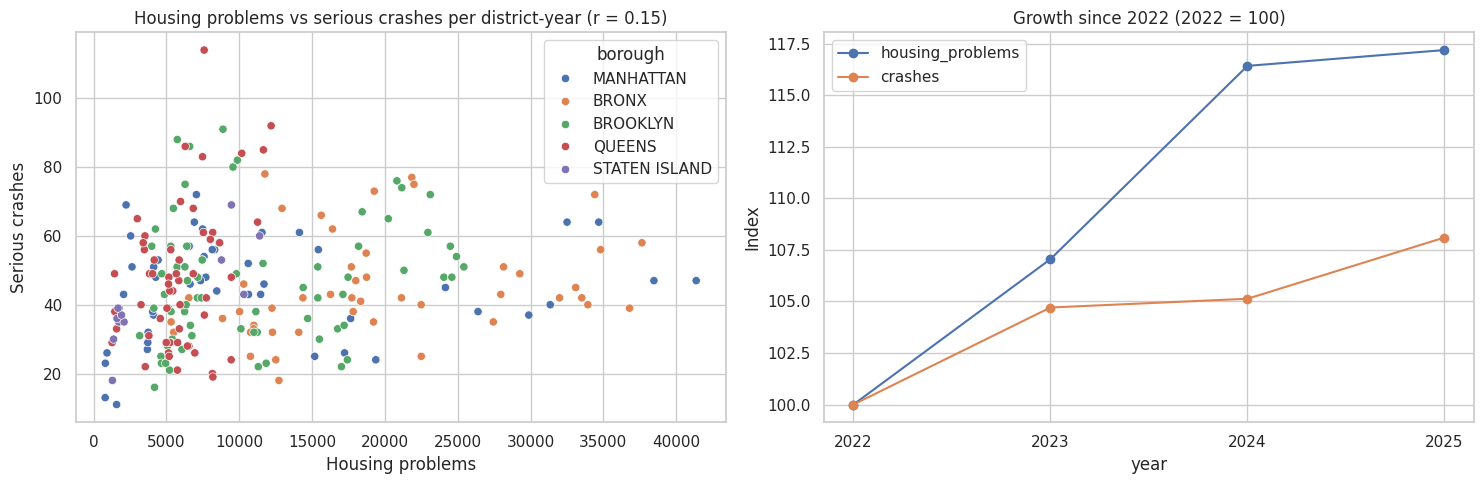

Saved integrated_cd_year.csv: 236 rows × 35 columns


In [34]:
# ============================================================
# 5.4 Validation: totals preserved + first cross-domain look
# ============================================================
checks = pd.DataFrame({
    'metric':      ['Housing problems', 'Crashes (with district)', 'Fatalities'],
    'before_merge': [len(df_housing), int(df_transport['in_integration'].sum()),
                     int(df_transport.loc[df_transport['in_integration'], 'total_fatalities'].sum())],
    'after_merge':  [df_integrated['housing_problems'].sum(), df_integrated['crashes'].sum(),
                     df_integrated['fatalities'].sum()],
})
checks['preserved'] = checks['before_merge'] == checks['after_merge']
display(checks)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=df_integrated, x='housing_problems', y='crashes', hue='borough', ax=axes[0])
r = df_integrated[['housing_problems', 'crashes']].corr().iloc[0, 1]
axes[0].set_title(f'Housing problems vs serious crashes per district-year (r = {r:.2f})')
axes[0].set_xlabel('Housing problems')
axes[0].set_ylabel('Serious crashes')

yearly = df_integrated.groupby('year')[['housing_problems', 'crashes']].sum()
(yearly / yearly.iloc[0] * 100).plot(ax=axes[1], marker='o')
axes[1].set_title('Growth since 2022 (2022 = 100)')
axes[1].set_ylabel('Index')
axes[1].set_xticks(YEARS)
plt.tight_layout()
plt.show()

df_integrated.to_csv(f'{SAVE_DIR}/integrated_cd_year.csv', index=False)
print(f'Saved integrated_cd_year.csv: {df_integrated.shape[0]} rows × {df_integrated.shape[1]} columns')

## 5.1 Integration Results

- **Integrated table:** 236 rows (59 community districts × 4 years) × 35 columns, saved as
  `integrated_cd_year.csv`.
- **Coverage:** all 236 district-years have both housing and crash data, so the merge created
  **0 missing values**. The fill-with-0 rule was kept as a safeguard but changed nothing.
- **Totals preserved:** housing problems (2,657,915), crashes with a district (10,837) and
  fatalities (654) are identical before and after the merge, so nothing was lost or double-counted.
- **Redundant column:** `cat_heat_hot_water` was identical to `heat_problems` and was dropped.
- **Borough consistency:** 119 crashes (1.10%) have a recorded borough that differs from the borough of
  their assigned district. These are mostly crashes on borough borders and bridges. The district
  (based on coordinates) is used, because it is the integration key.
- **Non-district crash codes** found during cleaning (164, 226–228, 355–356, 480–482) are joint interest
  areas such as large parks and airports, not residential districts. That's why they were reassigned
  to the nearest real district.

**First cross-domain observation:** across district-years, housing problems and serious crashes are
only **weakly correlated (r = 0.15)**. Housing problems grew 17% from 2022 to 2025, while serious crashes
grew 8%. The Bronx has the highest housing-problem volume but mid-range crash counts, while several
Queens and Brooklyn districts have high crash counts with fewer housing problems. The research questions
explore which *types* of housing problems and crashes are related.

 # 6. Export for the Website

The website is deployed on Render's free tier, which has **512 MB of RAM**. The cleaned housing data
(2.6M rows) cannot be loaded there, so we export **small pre-aggregated tables** instead. Each table
adds up exactly to the full cleaned data (verified with `assert`), so no information used by the charts
is lost.

| File | Rows | Used for |
|---|---|---|
| `integrated_cd_year.csv` | 236 | Cross-domain charts (district × year) |
| `housing_monthly.parquet` | ~100k | Housing patterns by month, category and type |
| `housing_nta.parquet` | ~900 | Neighbourhood-level complaint analysis |
| `cd_centroids.csv` | 59 | District centre points for the map |
| `crashes.parquet` | 11,953 | Crash-level charts (time, streets, severity) |

In [35]:
# ============================================================
# 6.1 Export small tables for the website
# (Render's free tier has 512 MB RAM, so the website cannot load 2.6M housing rows)
# ============================================================
import os

WEB_DIR = f'{SAVE_DIR}/web_data'
os.makedirs(WEB_DIR, exist_ok=True)

# (1) Housing problems per district × year × month × category × type  →  Q4, Q7, Q8
housing_monthly = (df_housing
                   .groupby(['cd_id', 'borough', 'year', 'month', 'major_category', 'type'], observed=True)
                   .size().reset_index(name='problems'))

# (2) Housing problems and complaints per neighbourhood × year  →  Q9
housing_nta = (df_housing.dropna(subset=['nta'])
               .groupby(['nta', 'borough', 'year'], observed=True)
               .agg(problems=('complaint_id', 'size'), complaints=('complaint_id', 'nunique'))
               .reset_index())

# (3) Centre point of each community district  →  Q5 map
cd_centroids = (df_housing.dropna(subset=['latitude'])
                .groupby('cd_id')[['latitude', 'longitude']].mean().reset_index()
                .merge(df_integrated[['cd_id', 'cd_label', 'borough']].drop_duplicates(), on='cd_id'))

# (4) Crashes: already small; keep only the columns the charts use
crash_cols = ['open_data_crash_id', 'crash_date', 'year', 'month', 'weekday', 'crash_hour', 'borough',
              'cd_id', 'zip_code', 'on_street', 'total_severe_injuries', 'total_non_severe_injuries',
              'total_fatalities', 'total_victims', 'latitude', 'longitude', 'in_integration']
crashes_web = df_transport[crash_cols].copy()

# Category columns → plain text, so the files load the same way everywhere
for t in (housing_monthly, housing_nta, cd_centroids, crashes_web):
    for c in t.select_dtypes(include='category').columns:
        t[c] = t[c].astype(str)
crashes_web['cd_id'] = crashes_web['cd_id'].astype('Int64')

# Verification: the small tables must add up to the full data
assert housing_monthly['problems'].sum() == len(df_housing)
assert len(cd_centroids) == df_integrated['cd_id'].nunique()

exports = {
    'integrated_cd_year.csv':  df_integrated,
    'housing_monthly.parquet': housing_monthly,
    'housing_nta.parquet':     housing_nta,
    'cd_centroids.csv':        cd_centroids,
    'crashes.parquet':         crashes_web,
}
for name, table in exports.items():
    path = f'{WEB_DIR}/{name}'
    table.to_csv(path, index=False) if name.endswith('.csv') else table.to_parquet(path, index=False)
    print(f'{name:<26} {len(table):>8,} rows × {table.shape[1]:>2} cols   {os.path.getsize(path) / 1e6:6.2f} MB')

print(f"\nCheck: housing_monthly sums to {housing_monthly['problems'].sum():,} problems = {len(df_housing):,} rows")
print(f'All website files saved to {WEB_DIR}')

integrated_cd_year.csv          236 rows × 35 cols     0.05 MB
housing_monthly.parquet      73,104 rows ×  7 cols     0.13 MB
housing_nta.parquet             888 rows ×  5 cols     0.02 MB
cd_centroids.csv                 59 rows ×  5 cols     0.00 MB
crashes.parquet              11,953 rows × 17 cols     0.35 MB

Check: housing_monthly sums to 2,657,915 problems = 2,657,915 rows
All website files saved to /content/drive/MyDrive/DEV_project_data/web_data


# 7. Research Questions

Each question has: the question and why it matters, the chart (an interactive Plotly function that is
reused unchanged on the website), the numbers behind the answer, and the answer itself.
All charts use the same small website files exported in Section 6, so the notebook and the website show
identical results.

| # | Question | Member |
|---|---|---|
| Q1 | Which community districts are double-burdened? | Member 1 |
| Q7 | How does the heating season differ across boroughs? | Member 1 |
| ... | (other members' questions) | ... |

In [36]:
# ============================================================
# 7.1 Setup: load the website files (same data the website uses)
# ============================================================
import pandas as pd
import numpy as np
import plotly.express as px

WEB = f'{SAVE_DIR}/web_data'
df_integrated      = pd.read_csv(f'{WEB}/integrated_cd_year.csv')
df_housing_monthly = pd.read_parquet(f'{WEB}/housing_monthly.parquet')
df_housing_nta     = pd.read_parquet(f'{WEB}/housing_nta.parquet')
df_centroids       = pd.read_csv(f'{WEB}/cd_centroids.csv')
df_crashes         = pd.read_parquet(f'{WEB}/crashes.parquet')

BOROUGH_COLORS = {'Manhattan': '#2557a7', 'Bronx': '#b5562f', 'Brooklyn': '#2f7d5b',
                  'Queens': '#8a4fa8', 'Staten Island': '#c7951c'}
BOROUGH_SHORT  = {'MANHATTAN': 'MN', 'BRONX': 'BX', 'BROOKLYN': 'BK', 'QUEENS': 'QN', 'STATEN ISLAND': 'SI'}
print('Website files loaded')

Website files loaded


## Q1. Which community districts are "double-burdened"?

**Question:** Which community districts rank in the **top quarter for both** housing maintenance
problems and serious traffic crashes (2022–2025)?

**Why it matters:** overall, housing problems and serious crashes are only weakly correlated
(r = 0.15 across district-years), so the two burdens usually fall on different places. The districts where
they *do* overlap are where residents face both unsafe homes and unsafe streets, and where coordinated
action by housing (HPD) and transport (DOT) agencies would help most.

**Method:** sum both measures per district over the selected years; mark the 75th percentile of each as a
dashed line; districts in the shaded top-right quadrant are double-burdened.

In [38]:
# ============================================================
# Q1: Which community districts are "double-burdened"?
# ============================================================
def double_burdened_table(df_integrated):
    """District totals over the selected years, with a flag for the top quarter on both measures."""
    d = (df_integrated.groupby(['cd_id', 'cd_label', 'borough'], as_index=False)
                      [['housing_problems', 'crashes']].sum())
    x_cut = d['housing_problems'].quantile(0.75)
    y_cut = d['crashes'].quantile(0.75)
    d['double_burdened'] = (d['housing_problems'] >= x_cut) & (d['crashes'] >= y_cut)
    d['crashes_per_10k_problems'] = (d['crashes'] / d['housing_problems'].replace(0, np.nan) * 10_000).round(1)
    return d, x_cut, y_cut


def build_q1(df_integrated):
    """Quadrant scatter: housing problems vs serious crashes per community district."""
    d, x_cut, y_cut = double_burdened_table(df_integrated)
    # Short labels (e.g. "BX 12") only on double-burdened points, so labels do not overlap
    short = d['borough'].map(BOROUGH_SHORT) + ' ' + (d['cd_id'] % 100).astype(str)
    d['label'] = np.where(d['double_burdened'], short, '')
    d['Borough'] = d['borough'].str.title()

    fig = px.scatter(
        d, x='housing_problems', y='crashes', color='Borough', text='label',
        color_discrete_map=BOROUGH_COLORS, hover_name='cd_label',
        hover_data={'label': False, 'Borough': False, 'housing_problems': ':,',
                    'crashes': ':,', 'crashes_per_10k_problems': True},
        labels={'housing_problems': 'Housing problems (count)', 'crashes': 'Serious crashes (count)',
                'crashes_per_10k_problems': 'Crashes per 10k problems'},
        title='Q1. Double-burdened districts: housing problems vs serious crashes')

    # Shade the "double-burdened" quadrant (top quarter on both axes)
    fig.add_shape(type='rect', x0=x_cut, x1=d['housing_problems'].max() * 1.05,
                  y0=y_cut, y1=d['crashes'].max() * 1.08,
                  fillcolor='rgba(200, 40, 40, 0.07)', line_width=0, layer='below')
    fig.add_vline(x=x_cut, line_dash='dash', line_color='gray',
                  annotation_text='Top 25% housing problems', annotation_position='bottom right')
    fig.add_hline(y=y_cut, line_dash='dash', line_color='gray',
                  annotation_text='Top 25% serious crashes', annotation_position='top left')

    fig.update_traces(marker=dict(size=10, line=dict(width=0.5, color='white')),
                      textposition='top center', textfont_size=10)
    fig.update_layout(template='plotly_white', height=560, legend_title_text='Borough')
    return fig


build_q1(df_integrated).show()

In [39]:
# ============================================================
# Q1: numbers for the answer
# ============================================================
q1_table, q1_x_cut, q1_y_cut = double_burdened_table(df_integrated)
q1_top = q1_table[q1_table['double_burdened']].sort_values('crashes', ascending=False)

print(f'Thresholds (75th percentile): {q1_x_cut:,.0f} housing problems | {q1_y_cut:,.0f} serious crashes')
print(f"Double-burdened districts: {len(q1_top)} of {len(q1_table)}")
print(q1_top['borough'].value_counts().to_string())
display(q1_top[['cd_label', 'housing_problems', 'crashes', 'crashes_per_10k_problems']])

r = q1_table[['housing_problems', 'crashes']].corr().iloc[0, 1]
print(f'Correlation across districts (4-year totals): r = {r:.2f}')

Thresholds (75th percentile): 64,194 housing problems | 221 serious crashes
Double-burdened districts: 5 of 59
borough
BROOKLYN     2
BRONX        2
MANHATTAN    1


,cd_label,housing_problems,crashes,crashes_per_10k_problems
28,Brooklyn CD 5,80667,282,35.0
23,Bronx CD 12,80814,276,34.2
37,Brooklyn CD 14,92976,227,24.4
15,Bronx CD 4,143687,225,15.7
11,Manhattan CD 12,147050,222,15.1


Correlation across districts (4-year totals): r = 0.17


### Q1 Answer

**5 of NYC's 59 community districts are double-burdened**: they rank in the top quarter for both housing
problems (≥ 64,194 over 2022–2025) and serious crashes (≥ 221, about 55 per year).

| District | Neighbourhoods | Housing problems | Serious crashes | Crashes per 10k problems |
|---|---|---|---|---|
| Brooklyn CD 5 | East New York, Cypress Hills | 80,667 | 282 | 35.0 |
| Bronx CD 12 | Williamsbridge, Wakefield, Eastchester | 80,814 | 276 | 34.2 |
| Brooklyn CD 14 | Flatbush, Midwood | 92,976 | 227 | 24.4 |
| Bronx CD 4 | Highbridge, Concourse | 143,687 | 225 | 15.7 |
| Manhattan CD 12 | Washington Heights, Inwood | 147,050 | 222 | 15.1 |

**Findings:**
- The double burden is concentrated in the **Bronx and Brooklyn** (4 of 5 districts), with one district in
  upper Manhattan. No district in Queens or Staten Island qualifies.
- The five districts fall into **two different profiles**:
  - **Crash-led:** Brooklyn CD 5 and Bronx CD 12 have the **highest serious-crash counts** of the group
    (282 and 276) with mid-to-high housing volume, about 35 crashes per 10,000 housing problems.
  - **Housing-led:** Bronx CD 4 and Manhattan CD 12 have among the **highest housing-problem counts in the
    city** (~144k–147k), but crash counts only just above the threshold (~15 per 10,000).
- Across districts, the two measures are only **weakly associated (r = 0.17)**. If the two burdens were
  completely unrelated, about 3–4 districts (25% × 25% of 59) would land in the top quadrant by chance;
  5 is only slightly more. **High housing problems and high serious crashes mostly occur in different
  districts**, and these five are the exceptions where they overlap.

**Benefit to NYC:** these five districts are where joint action by HPD (housing inspections) and DOT
(street safety, e.g. Vision Zero redesigns) would reach residents facing both risks at once. Brooklyn CD 5
and Bronx CD 12 are the strongest candidates for street-safety work; Bronx CD 4 and Manhattan CD 12
for housing enforcement.

**Limitations:** these are raw counts, not adjusted for population, area or road length, so large, dense
districts rank higher. Serious crashes are rare: Bronx CD 4 and Manhattan CD 12 are only 1–4 crashes
above the threshold, so their status could change with one year's data. Housing problems are
tenant-reported complaints, which reflect reporting behaviour as well as actual building conditions.

## Q7. How does the heating-season pattern of heat/hot-water problems differ across boroughs?

**Question:** In which months do heat and hot-water problems occur in each borough, and does the
length or intensity of the "heating crisis" differ between boroughs?

**Why it matters:** NYC law requires landlords to provide heat from **1 October to 31 May**. Heat/hot-water
is one of the largest housing problem categories, and a lack of heat in winter is a health risk.
Knowing when each borough peaks helps HPD schedule inspections and outreach.

**Method:** filter heat/hot-water problems, count them per borough and month, and convert each borough's
counts to **% of its own yearly total**. This makes Staten Island (few problems) comparable to the Bronx
(many). Each row of the heatmap sums to 100%.

In [40]:
# ============================================================
# Q7: How does the heating season differ across boroughs?
# ============================================================
MONTH_NAMES = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
BOROUGH_ORDER = ['BRONX', 'BROOKLYN', 'MANHATTAN', 'QUEENS', 'STATEN ISLAND']


def heat_season_table(df_housing_monthly):
    """% of each borough's heat/hot-water problems that fall in each calendar month."""
    heat = df_housing_monthly[df_housing_monthly['major_category'] == 'HEAT/HOT WATER']
    counts = (heat.groupby(['borough', 'month'])['problems'].sum()
                  .unstack(fill_value=0)
                  .reindex(columns=range(1, 13), fill_value=0))
    counts = counts.reindex([b for b in BOROUGH_ORDER if b in counts.index])
    share = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0) * 100
    return share, counts


def build_q7(df_housing_monthly):
    """Heatmap: share of each borough's heat problems per month (each row sums to 100%)."""
    share, counts = heat_season_table(df_housing_monthly)
    fig = px.imshow(
        share.round(1), x=MONTH_NAMES, y=[b.title() for b in share.index],
        color_continuous_scale='OrRd', aspect='auto', text_auto='.0f',
        labels={'x': 'Month', 'y': 'Borough', 'color': '% of borough\'s heat problems'},
        title='Q7. Heating season by borough: share of heat/hot-water problems per month')
    fig.update_traces(
        customdata=counts.values,
        hovertemplate='%{y}, %{x}<br>Share: %{z:.1f}%<br>Problems: %{customdata:,}<extra></extra>')
    fig.update_layout(template='plotly_white', height=420,
                      coloraxis_colorbar=dict(title='% of year', ticksuffix='%'))
    return fig


build_q7(df_housing_monthly).show()

In [41]:
# ============================================================
# Q7: numbers for the answer
# ============================================================
q7_share, q7_counts = heat_season_table(df_housing_monthly)
season = [10, 11, 12, 1, 2, 3, 4, 5]   # NYC heat season: 1 October – 31 May

q7_summary = pd.DataFrame({
    'heat_problems':     q7_counts.sum(axis=1),
    'peak_month':        q7_share.idxmax(axis=1).map(lambda m: MONTH_NAMES[m - 1]),
    'peak_month_%':      q7_share.max(axis=1).round(1),
    'Dec_to_Feb_%':      q7_share[[12, 1, 2]].sum(axis=1).round(1),
    'in_heat_season_%':  q7_share[season].sum(axis=1).round(1),
    'Jun_to_Sep_%':      q7_share[[6, 7, 8, 9]].sum(axis=1).round(1),
})
display(q7_summary)

,heat_problems,peak_month,peak_month_%,Dec_to_Feb_%,in_heat_season_%,Jun_to_Sep_%
borough,,,,,,
BRONX,208047,Dec,19.2,50.7,94.3,5.7
BROOKLYN,172201,Dec,18.7,49.0,94.2,5.8
MANHATTAN,133136,Dec,18.4,47.6,93.4,6.6
QUEENS,86953,Dec,19.2,49.6,94.6,5.4
STATEN ISLAND,8371,Dec,19.2,48.9,92.4,7.6


### Q7 Answer

**The heating season is almost identical in every borough. What differs is the volume, not the timing.**

| Borough | Heat problems | Peak month | Dec–Feb | Oct–May (legal heat season) | Jun–Sep |
|---|---|---|---|---|---|
| Bronx | 208,047 | Dec (19.2%) | 50.7% | 94.3% | 5.7% |
| Brooklyn | 172,201 | Dec (18.7%) | 49.0% | 94.2% | 5.8% |
| Manhattan | 133,136 | Dec (18.4%) | 47.6% | 93.4% | 6.6% |
| Queens | 86,953 | Dec (19.2%) | 49.6% | 94.6% | 5.4% |
| Staten Island | 8,371 | Dec (19.2%) | 48.9% | 92.4% | 7.6% |

**Findings:**
- **Same timing everywhere:** all five boroughs peak in **December** (18–19% of the year's heat problems in
  one month), and about **half of all heat problems occur in just three months (December–February)**.
- **92–95% fall inside the legal heat season** (1 October – 31 May) in every borough; the spread between
  boroughs is under 3 percentage points.
- **Summer is not zero:** 5–8% of problems occur June–September. The category includes **hot water**,
  which is needed all year, so these are likely hot-water failures. Staten Island (7.6%) and Manhattan
  (6.6%) have the highest summer shares.
- **Volume differs enormously:** heat/hot-water problems make up **608,708 problems, 22.9% of all housing
  problems**. The Bronx alone has 208,047, **2.4× Queens and 25× Staten Island**.

**Benefit to NYC:** because every borough peaks at the same time, HPD cannot shift inspectors between
boroughs during winter. Capacity has to be added citywide for December–February, with the largest share
going to the Bronx and Brooklyn.

**Limitations:** the chart shows **shares**, which hide volume differences (the hover shows the counts).
Heat and hot water are combined in one category, so the two cannot be separated. The pattern is averaged
over 4 winters, so a single very cold or mild winter is smoothed out. Complaints measure tenants
reporting a problem, not confirmed heating failures.